# 06 — Frozen evaluation: independent confirmation and statistics

**Stage.** Final evaluation of the architecture frozen in Notebook 05 on reserved workload seeds that no earlier stage generated, measured on Raspberry Pi 5.

**Goal.** Quantify, with prespecified inference, how much complete request-phase CPU the frozen SCAR-MLKEM controller saves against standard seed-only ML-KEM-768 reconstruction, and how it compares with strong fixed cache policies, while reporting response tails, memory, lifecycle discipline and computational efficiency.

**Research questions.** RQ5a (primary): is the paired CPU saving of SCAR-MLKEM against seed-only reconstruction positive, and how large is it with its uncertainty? RQ5b (secondary): is SCAR-MLKEM lower in CPU than public S3-FIFO, SIEVE, LeCaR and TinyLFU after multiplicity adjustment? RQ5c: are p95/p99 response, memory and secret-lifetime discipline preserved? RQ5d: in which workload regimes does the adaptive controller gain or lose?

**Data.** One new campaign planned at the end of Notebook 05: ten families × six reserved seeds × two arenas × six policies = 720 native sessions of 1000 decapsulation requests, acquired here exactly once. Development data are not reused for inference.

**Previous stages.** Notebook 05 froze the method, the competitor set, the endpoints and the inference rules before this campaign was launched; the next section checks that nothing changed since.

**Boundaries.** Analysis on the MacBook, timing on the Pi over visible SSH commands. Energy is not measured. No parameter is changed after the test is observed; a technical replay of this notebook verifies the saved campaign and recomputes the statistics without new acquisition. One board, controlled schedules and the stated threat-model limits bound every conclusion.

In [1]:
from pathlib import Path
import hashlib, io, json, os, re, shlex, subprocess, sys, tarfile, textwrap, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Image, Markdown, clear_output

NB = "06"
# Resolve the repository root from either the root directory or notebooks/.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks").is_dir() and (p / "dataset").is_dir()), None)
assert ROOT is not None, "run this notebook from inside the repository"
def relocate(rel):
    """Map a path recorded at acquisition time (original project layout) onto this repository's layout."""
    rel = str(rel)
    for old, new in (("Dataset/Raw/PiExperiments/", "dataset/raw/"), ("Dataset/Raw/", "dataset/raw/"), ("Raw/", "raw/"),
                     ("Dataset/Interim/", "dataset/interim/"), ("Dataset/Processed/", "dataset/processed/"),
                     ("Dataset/Splits/", "dataset/splits/"), ("Dataset/Provenance/", "dataset/provenance/"),
                     ("Artifacts/Models/", "support/models/"), ("Artifacts/Binaries/", "support/binaries/"),
                     ("Configs/", "support/configs/"), ("Manifests/", "support/manifests/"), ("Native/", "support/native/"),
                     ("Reports/CoreCalibration/", "support/calibration/"), ("Tables/", "artifacts/"), ("Figures/", "figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
def acquisition_path(path):
    """Inverse of relocate: a repository path written in the acquisition-time layout used inside frozen records."""
    path = Path(path)
    rel = str(path.resolve().relative_to(ROOT)) if path.is_absolute() else str(path)
    for old, new in (("dataset/raw/MLKEM_TestVectors/", "Dataset/Raw/MLKEM_TestVectors/"), ("dataset/raw/IoT23/", "Dataset/Raw/IoT23/"),
                     ("dataset/raw/", "Dataset/Raw/PiExperiments/"), ("dataset/interim/", "Dataset/Interim/"),
                     ("dataset/processed/", "Dataset/Processed/"), ("dataset/splits/", "Dataset/Splits/"),
                     ("dataset/provenance/", "Dataset/Provenance/"), ("support/models/", "Artifacts/Models/"),
                     ("support/binaries/", "Artifacts/Binaries/"), ("support/configs/", "Configs/"), ("support/manifests/", "Manifests/"),
                     ("support/native/", "Native/"), ("support/calibration/", "Reports/CoreCalibration/"),
                     ("artifacts/", "Tables/"), ("figures/", "Figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
DATA, TABLES, FIGURES = ROOT / "dataset", ROOT / "artifacts", ROOT / "figures"
RAW, INTERIM = DATA / "raw", DATA / "interim"
MANIFESTS, CONFIGS, CALIBRATION = ROOT / "support/manifests", ROOT / "support/configs", ROOT / "support/calibration"
for p in (TABLES, FIGURES, INTERIM, MANIFESTS / "NotebookRuns"):
    p.mkdir(parents=True, exist_ok=True)
RNG_SEED = 20261020
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
# Three decimals for metrics; scientific notation for very small nonzero values so that a p-value never prints as 0.000.
pd.set_option("display.float_format", lambda v: f"{v:.2e}" if 0 < abs(v) < 1e-3 else f"{v:.3f}")
try:
    font_manager.findfont("Times New Roman", fallback_to_default=False); FONT_FAMILY = "Times New Roman"
except ValueError:
    FONT_FAMILY = "serif"  # the published figures use Times New Roman; any serif font keeps the layout
mpl.rcParams.update({"font.family": FONT_FAMILY, "font.size": 18,
    "axes.titlesize": 20, "axes.labelsize": 20, "xtick.labelsize": 18,
    "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
    "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
    "legend.frameon": False})
COLORS = {"none": "#4D4D4D", "public_s3": "#0072B2", "sieve": "#009E73",
          "lecar": "#CC79A7", "tiny": "#E69F00", "scar": "#D55E00"}
LABELS = {"none": "Seed-only (standard)", "public_s3": "Public S3-FIFO",
          "sieve": "SIEVE", "lecar": "LeCaR", "tiny": "TinyLFU", "scar": "SCAR-MLKEM"}
POLICIES = ["none", "public_s3", "sieve", "lecar", "tiny", "scar"]
FAMILIES = ["uniform", "poisson", "zipf", "bursty", "periodic", "nonstationary",
            "abrupt", "thrashing", "hotcold", "varying_contexts"]
ARENAS = [32768, 65536]
COST_NAMES = ["C00", "C01", "C10", "C11", "addP", "addS", "eraseP", "eraseS"]

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()
def sha_bytes(data):
    return hashlib.sha256(data).hexdigest()
def read_json(path):
    return json.loads(Path(path).read_text())
def canonical(obj):
    return (json.dumps(obj, sort_keys=True, indent=2, allow_nan=False) + "\n").encode()
def write_json(path, obj):
    """Write once; an existing identical file is accepted, a different one is refused."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    data = canonical(obj)
    if path.exists():
        assert path.read_bytes() == data, f"refusing to overwrite a different {path.name}"
        return path
    path.write_bytes(data); return path
def save_table(frame, name, *, show=True, index=False):
    frame.to_csv(TABLES / f"{NB}_{name}.csv", index=index)
    if show:
        display(frame if index else frame.reset_index(drop=True))
def save_figure(fig, name, source=None):
    """Save PNG and PDF at 350 DPI, then show the saved PNG exactly once."""
    fig.set_layout_engine("constrained")
    png, pdf = FIGURES / f"{NB}_{name}.png", FIGURES / f"{NB}_{name}.pdf"
    fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=0.15); fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=0.15)
    plt.close(fig)
    if source is not None:
        source.to_csv(TABLES / f"{NB}_{name}_source.csv", index=False)
    display(Image(filename=str(png), width=900))
def check_font_sizes(fig):
    sizes = {round(t.get_fontsize(), 1) for t in fig.findobj(mpl.text.Text) if t.get_text().strip()}
    assert sizes and min(sizes) >= 18 and max(sizes) <= 20, sizes
# Raspberry Pi 5 transport: the Pi executes native cryptographic processes; this kernel stays on the MacBook.
PI_SETUP = Path(os.environ.get("PI_SETUP_DIR", "~/.scar_mlkem_pi")).expanduser()
PI_ENABLED = (PI_SETUP / "ssh_config").is_file()  # without a board every saved campaign is verified offline
PI_ALIAS, PI_REMOTE_ROOT = "nazira-pi", "/home/research/Nazira_Crystals-Cyber"
PI_BASE = ["ssh", "-F", str(PI_SETUP / "ssh_config"), "-o", "BatchMode=yes", "-o", "ConnectTimeout=8"]

def pi_candidates():
    """Primary mDNS alias first, then IPv6 link-local fallbacks on active interfaces."""
    yield []
    try:
        host = subprocess.run(["dscacheutil", "-q", "host", "-a", "name", "raspberrypi.local"],
                              capture_output=True, text=True, timeout=5).stdout
    except (OSError, subprocess.SubprocessError):
        host = ""
    v6 = re.findall(r"ipv6_address:\s*(\S+)", host)
    ifaces = re.findall(r"^(en\d+):", subprocess.run(["ifconfig"], capture_output=True, text=True).stdout, re.M)
    for addr in v6:
        for ifc in ifaces:
            yield ["-o", f"HostName={addr}%%{ifc}"]

def pi_run(command, *, input_bytes=None, timeout=120, attempts=30):
    """Run one remote shell command; returns CompletedProcess or raises after all transports fail.
    The USB-LAN link to the Pi drops for short periods, so each command tolerates about five minutes of outage."""
    if not PI_ENABLED:
        raise ConnectionError("Raspberry Pi transport is not configured (set PI_SETUP_DIR)")
    last = None
    for attempt in range(attempts):
        for extra in pi_candidates():
            try:
                result = subprocess.run(PI_BASE + extra + [PI_ALIAS, command], input=input_bytes,
                                        capture_output=True, timeout=timeout)
            except subprocess.TimeoutExpired as exc:
                last = exc; continue
            if result.returncode == 255:
                last = result; continue
            return result
        time.sleep(10)
    raise ConnectionError(f"Raspberry Pi unreachable after {attempts} attempts: {last}")

def pi_text(command, **kw):
    r = pi_run(command, **kw); assert r.returncode == 0, r.stderr.decode()[:400]
    return r.stdout.decode()

def pi_sudo(command, **kw):
    """Only CPU-governor changes need sudo; the password is read from the project's private credential file and never shown."""
    secret = read_json(PI_SETUP / "private/credentials.json")["password"] + "\n"
    r = pi_run("sudo -S -p '' " + command, input_bytes=secret.encode(), **kw)
    assert r.returncode == 0, "sudo command failed"
    return r.stdout.decode()

def pi_governor(value=None, frequency_khz=None):
    """Set the CPU governor on every policy; with the userspace governor also pin the frequency."""
    if value is not None:
        script = "for c in /sys/devices/system/cpu/cpufreq/policy*/scaling_governor; do echo " + value + " > $c; done"
        if frequency_khz is not None:
            script += "; for c in /sys/devices/system/cpu/cpufreq/policy*/scaling_setspeed; do echo " + str(int(frequency_khz)) + " > $c; done"
        pi_sudo("sh -c " + shlex.quote(script))
    return pi_text("cat /sys/devices/system/cpu/cpu2/cpufreq/scaling_governor").strip()

def pi_background_load(cores):
    """Start one busy loop per listed core (interference control); returns nothing, use pi_stop_background_load() to end."""
    for core in cores:
        pi_text(f"setsid nohup taskset -c {int(core)} yes > /dev/null 2>&1 < /dev/null & echo started")
    count = pi_text("pgrep -x -c yes || true").strip()
    assert count.isdigit() and int(count) >= len(cores), count

def pi_stop_background_load():
    pi_text("pkill -x yes || true")

def pi_upload(paths):
    """Upload project-relative files to the same relative paths on the Pi."""
    payload = io.BytesIO()
    with tarfile.open(fileobj=payload, mode="w:gz") as tar:
        for p in paths:
            tar.add(p, arcname=acquisition_path(Path(p).resolve()))
    pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && tar -xzf -", input_bytes=payload.getvalue())

def pi_fetch(relative_dir):
    """Fetch a remote directory into the identical local path; existing files must be byte-identical."""
    for attempt in range(4):
        data = pi_run(f"cd {shlex.quote(PI_REMOTE_ROOT)} && tar -czf - {shlex.quote(relative_dir)}", timeout=900)
        if data.returncode == 0:
            break
        time.sleep(5)
    assert data.returncode == 0, data.stderr.decode()[:300]
    with tarfile.open(fileobj=io.BytesIO(data.stdout), mode="r:gz") as tar:
        for member in tar:
            target = (ROOT / relocate(member.name)).resolve()
            assert target.is_relative_to(ROOT / relocate(relative_dir))
            if member.isdir():
                target.mkdir(parents=True, exist_ok=True); continue
            assert member.isfile()
            content = tar.extractfile(member).read()
            if target.exists():
                assert target.read_bytes() == content, member.name
            else:
                target.parent.mkdir(parents=True, exist_ok=True); target.write_bytes(content)
WORKER_SOURCE = r'''#!/usr/bin/env python3
"""Sequential native campaign worker for Raspberry Pi 5.
Runs every planned process exactly once in registered order. No retry, no selection,
no analysis. Every outcome, including failures, is recorded."""
import hashlib, json, os, platform, re, signal, subprocess, sys, time
from pathlib import Path

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

def write(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".partial")
    tmp.write_text(json.dumps(obj, sort_keys=True, indent=2, allow_nan=False) + "\n")
    os.replace(tmp, path)

def read_sys(p):
    try:
        return Path(p).read_text().strip()
    except OSError as exc:
        return "unavailable:" + type(exc).__name__

def environment(cpu):
    try:
        throttled = subprocess.run(["vcgencmd", "get_throttled"], capture_output=True, text=True, timeout=5).stdout.strip()
    except (OSError, subprocess.SubprocessError) as exc:
        throttled = "unavailable:" + type(exc).__name__
    return dict(governor=read_sys(f"/sys/devices/system/cpu/cpu{cpu}/cpufreq/scaling_governor"),
                frequency_khz=read_sys(f"/sys/devices/system/cpu/cpu{cpu}/cpufreq/scaling_cur_freq"),
                temperature_millic=read_sys("/sys/class/thermal/thermal_zone0/temp"),
                throttled=throttled, loadavg=read_sys("/proc/loadavg"), kernel=platform.release(),
                machine=platform.machine(), utc=time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()))

def kv(text):
    values = {}
    for key, val in re.findall(r"([A-Za-z_]\w*)=([^\s]+)", text):
        if key in values and values[key] != val:
            values[key + "__conflict"] = val
        values.setdefault(key, val)
    return values

def main():
    assert len(sys.argv) == 3, "usage: worker.py SPEC_JSON SPEC_SHA256"
    spec_path, expected = Path(sys.argv[1]), sys.argv[2]
    assert sha(spec_path) == expected, "spec digest mismatch"
    spec = json.loads(spec_path.read_text())
    root = Path(spec["remote_root"]); os.chdir(root)
    assert sha(spec["binary"]) == spec["binary_sha256"] and sha(spec["library"]) == spec["library_sha256"]
    raw = root / spec["raw_dir"]; raw.mkdir(parents=True, exist_ok=False)
    write(raw / "spec.json", spec)
    cpu, names = spec["cpu"], spec["cost_names"]
    cost_args = [format(spec["costs_ns"][k], ".17g") for k in names]
    records, passed, failed, aborted = [], 0, 0, None
    first_env = environment(cpu)
    for index, row in enumerate(spec["plan"]):
        before = environment(cpu)
        before["scheduler"] = os.sched_getscheduler(0)
        wrong_frequency = "frequency_khz" in spec and before["frequency_khz"] != str(spec["frequency_khz"])
        if before["governor"] != spec["governor"] or not before["throttled"].endswith("=0x0") or wrong_frequency:
            aborted = dict(index=index, reason="environment", environment=before); break
        args = ["run", row["session_id"], row["family"], str(row["seed"]), str(spec["requests"]),
                str(spec["contexts"]), str(spec["interval_us"]), spec["split"], row["policy"],
                str(row["arena_bytes"]), str(row["ttl_ms"]), str(spec["guard_us"]), str(spec["horizon_ms"]),
                str(spec["history_capacity"]), str(row["components"])] + cost_args + [str(spec["drift"])]
        argv = ["taskset", "-c", str(cpu), spec["binary"]] + args
        env = {k: v for k, v in os.environ.items() if not k.startswith("SCAR_")}
        if row["policy"] == "scar":
            env.update(SCAR_K=str(spec["scar"]["k"]), SCAR_NU=str(spec["scar"]["nu"]), SCAR_MARGIN=str(spec["scar"]["margin"]))
        base = raw / row["session_id"]
        started = time.monotonic()
        with open(str(base) + ".stdout.csv", "wb") as out, open(str(base) + ".stderr.txt", "wb") as err:
            proc = subprocess.Popen(argv, stdout=out, stderr=err, env=env, stdin=subprocess.DEVNULL, start_new_session=True)
            try:
                rc = proc.wait(timeout=spec["timeout_seconds"])
            except subprocess.TimeoutExpired:
                os.killpg(proc.pid, signal.SIGKILL); rc = proc.wait()
        wall = time.monotonic() - started
        after = environment(cpu)
        meta = kv(Path(str(base) + ".stderr.txt").read_text(errors="replace"))
        rows = sum(1 for _ in open(str(base) + ".stdout.csv", "rb")) - 1
        ok = rc == 0 and meta.get("native_success") == "1" and meta.get("request_count") == str(spec["requests"]) and rows == spec["requests"]
        status = "passed" if ok else "failed"
        passed += ok; failed += (not ok)
        record = dict(index=index, row=row, argv=argv, before=before, after=after, returncode=rc,
                      wall_seconds=wall, status=status, metadata=meta, stdout_rows=rows,
                      stdout_sha256=sha(str(base) + ".stdout.csv"), stderr_sha256=sha(str(base) + ".stderr.txt"))
        write(str(base) + ".record.json", record); records.append(record)
        write(raw / "progress.json", dict(attempted=index + 1, passed=passed, failed=failed, planned=len(spec["plan"])))
        time.sleep(spec["cooldown_seconds"])
    files = {str(p.relative_to(raw)): sha(p) for p in sorted(raw.rglob("*")) if p.is_file() and p.name != "progress.json"}
    write(raw / "done.json", dict(status="aborted" if aborted else "completed", aborted=aborted,
          attempted=len(records), passed=passed, failed=failed, planned=len(spec["plan"]),
          spec_sha256=expected, environment_first=first_env, environment_last=environment(cpu),
          python=platform.python_version(), files=files))

if __name__ == "__main__":
    main()
'''
def campaign_plan_rows(families, seeds_by_family, arenas, settings, split):
    """Enumerate processes: one native session per (family, seed, arena, setting), in registered order."""
    rows = []
    for family in families:
        for seed in seeds_by_family[family]:
            for arena in arenas:
                for s in settings:
                    rows.append(dict(session_id=f"{split}_{family}_{seed}_{arena // 1024}k_{s['name']}",
                                     family=family, seed=int(seed), arena_bytes=int(arena), setting=s["name"],
                                     policy=s["policy"], components=int(s["components"]), ttl_ms=int(s["ttl_ms"])))
    assert len({r["session_id"] for r in rows}) == len(rows)
    return rows

def registered_seeds(exclude=None):
    """Every seed that any manifest or configuration in the project has ever registered,
    optionally ignoring one campaign's own registration folder (so replays stay consistent)."""
    seeds = set()
    for folder, pattern in ((MANIFESTS, "*.json"), (CONFIGS, "*.csv"), (CONFIGS, "*.json")):
        for p in folder.rglob(pattern):
            if exclude is not None and p.resolve().is_relative_to(Path(exclude).resolve()):
                continue
            try:
                text = p.read_text()
            except (OSError, UnicodeDecodeError):
                continue
            seeds.update(int(m) for m in re.findall(r'"(?:seed|workload_seed)"\s*:\s*"?(\d{4,9})', text))
            if pattern.endswith("csv"):
                seeds.update(int(m) for m in re.findall(r"\b(\d{6,8})\b", text))
    return seeds

def register_campaign(campaign, identity, plan, *, split, native, extra):
    """Immutable registration before acquisition: spec, worker and digests are written once."""
    reg = MANIFESTS / campaign / identity
    raw_rel = f"Dataset/Raw/PiExperiments/{campaign}/{identity}"
    spec = dict(schema="scar_mlkem_campaign_v2", campaign=campaign, identity=identity, split=split,
                remote_root=PI_REMOTE_ROOT, raw_dir=raw_rel, plan=plan, requests=1000, contexts=64,
                interval_us=500, guard_us=500, horizon_ms=10, history_capacity=1000, drift=1, cpu=2,
                governor="performance", timeout_seconds=120, cooldown_seconds=0.3,
                scar=dict(k=0, nu=2, margin=0), cost_names=COST_NAMES)
    spec.update(native); spec.update(extra)
    worker = reg / "worker.py"
    reg.mkdir(parents=True, exist_ok=True)
    if not worker.exists():
        worker.write_text(WORKER_SOURCE)
    # A campaign binds the worker it was registered with; later worker revisions never rewrite an existing registration.
    spec["worker_sha256"] = sha(worker)
    spec_path = write_json(reg / "spec.json", spec)
    registration = reg / "registration.json"
    if registration.exists():
        assert read_json(registration)["spec_sha256"] == sha(spec_path), "registered spec differs from the current plan"
    else:
        write_json(registration, dict(registered_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                   spec_sha256=sha(spec_path), worker_sha256=spec["worker_sha256"], processes=len(plan)))
    return reg, spec

def run_campaign(reg, spec, *, poll_seconds=15, launch_prefix="", as_root=False, prepare=None, finish=None):
    """Upload, start the Pi worker once, poll, fetch raw results and verify every digest.
    A completed local copy is verified instead of re-acquired, so replays never relaunch native work."""
    raw_local = ROOT / relocate(spec["raw_dir"]); done_local = raw_local / "done.json"
    spec_rel = acquisition_path((reg / "spec.json")); worker_rel = acquisition_path((reg / "worker.py"))
    spec_digest = sha(reg / "spec.json")
    if not done_local.exists():
        pi_upload([reg / "spec.json", reg / "worker.py"])
        remote_done = f"{spec['raw_dir']}/done.json"
        exists = pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && test -e {shlex.quote(spec['raw_dir'])} && echo yes || echo no").strip()
        if exists == "no":
            assert pi_governor(spec["governor"], spec.get("frequency_khz")) == spec["governor"]
            if prepare is not None:
                prepare()
            start_cmd = f"cd {shlex.quote(PI_REMOTE_ROOT)} && setsid nohup {launch_prefix}python3 {shlex.quote(worker_rel)} {shlex.quote(spec_rel)} {spec_digest} > {shlex.quote(spec_rel + '.worker.log')} 2>&1 < /dev/null & echo started"
            try:
                response = (pi_sudo("sh -c " + shlex.quote(start_cmd)) if as_root else pi_text(start_cmd)).strip()
            except (ConnectionError, AssertionError):
                # The link can drop after the command was delivered; the worker refuses to start twice (raw directory exists).
                response = "start response lost; worker presence verified on the next poll"
            if not (reg / "start.receipt.json").exists():
                write_json(reg / "start.receipt.json", dict(started_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"), response=response))
        while True:
            try:
                status = pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && cat {shlex.quote(spec['raw_dir'])}/progress.json 2>/dev/null; test -f {shlex.quote(remote_done)} && echo DONE; true")
            except ConnectionError:
                time.sleep(poll_seconds); continue
            finished = status.strip().endswith("DONE")
            progress = re.search(r'"attempted":\s*(\d+)', status)
            clear_output(wait=True)
            print(f"Raspberry Pi campaign {spec['identity']}: {progress.group(1) if progress else 0}/{len(spec['plan'])} processes" + (" — complete" if finished else " — running"))
            if finished:
                break
            time.sleep(poll_seconds)
        pi_fetch(spec["raw_dir"])
        if finish is not None:
            finish()
        restored = pi_governor("ondemand")
        write_json(reg / "governor_restored.json", dict(governor=restored, utc=datetime.now(timezone.utc).isoformat(timespec="seconds")))
        clear_output(wait=True)
    done = read_json(done_local)
    assert done["spec_sha256"] == spec_digest
    for name, digest in done["files"].items():
        assert sha(raw_local / name) == digest, name
    return done

def load_campaign(spec, done):
    """One row per native process: identifiers, complete request-phase CPU, hits, tails, memory, lifecycle."""
    raw_local = ROOT / relocate(spec["raw_dir"]); rows = []
    for row in spec["plan"]:
        rec = read_json(raw_local / (row["session_id"] + ".record.json"))
        meta = rec["metadata"]
        item = dict(row, status=rec["status"], wall_seconds=rec["wall_seconds"],
                    temperature_c=int(rec["before"]["temperature_millic"]) / 1000,
                    frequency_mhz=int(rec["before"]["frequency_khz"]) / 1000 if rec["before"]["frequency_khz"].isdigit() else np.nan,
                    scheduler=rec["before"].get("scheduler", 0))
        if rec["status"] == "passed":
            frame = pd.read_csv(raw_local / (row["session_id"] + ".stdout.csv"))
            assert len(frame) == spec["requests"] and frame.success.eq(1).all()
            item.update(cpu_us=int(meta["request_phase_thread_cpu_ns"]) / spec["requests"] / 1000,
                        wall_us=int(meta["request_phase_wall_ns"]) / spec["requests"] / 1000,
                        public_hit=frame.public_hit.mean(), secret_hit=frame.secret_hit.mean(),
                        public_admitted=frame.public_admitted.mean(), secret_admitted=frame.secret_admitted.mean(),
                        service_p50_us=frame.service_ns.quantile(0.5) / 1000, service_p95_us=frame.service_ns.quantile(0.95) / 1000,
                        service_p99_us=frame.service_ns.quantile(0.99) / 1000, response_p95_us=frame.response_ns.quantile(0.95) / 1000,
                        response_p99_us=frame.response_ns.quantile(0.99) / 1000,
                        planning_ns=frame.planning_ns.mean(), decapsulation_ns=frame.decapsulation_ns.mean(),
                        reconstruction_ns=frame.reconstruction_ns.mean(), public_prepare_ns=frame.public_prepare_ns.mean(),
                        peak_rss_bytes=int(meta["peak_rss_bytes"]), retained_mapping_bytes=int(meta["total_retained_mapping_bytes"]),
                        peak_occupied_bytes=int(meta["peak_occupied_bytes"]), policy_bytes=int(meta.get("policy_bytes", 0)),
                        late_clear_count=int(meta["late_clear_count"]), max_lateness_us=int(meta["max_lateness_ns"]) / 1000,
                        secret_max_residency_ms=int(meta["secret_max_residency_ns"]) / 1e6, zeroizations=int(meta["zeroizations"]))
        rows.append(item)
    frame = pd.DataFrame(rows)
    frame["stratum"] = frame.family + " / " + (frame.arena_bytes // 1024).astype(str) + " KiB"
    return frame

def stratified_bootstrap(values, strata, denominator=None, reps=10000, seed=RNG_SEED):
    """Percentile bootstrap of the equal-stratum mean (or of 100 × the ratio of equal-stratum means when a
    denominator is given), resampling sessions within each stratum. Returns point, 2.5 %, 97.5 % and 5 % quantiles."""
    rng = np.random.default_rng(seed); values = np.asarray(values, float); strata = np.asarray(strata)
    den = None if denominator is None else np.asarray(denominator, float)
    groups = [np.flatnonzero(strata == s) for s in np.unique(strata)]
    def statistic(index_sets):
        num = np.mean([values[g].mean() for g in index_sets])
        return num if den is None else 100 * num / np.mean([den[g].mean() for g in index_sets])
    estimates = np.array([statistic([rng.choice(g, len(g), replace=True) for g in groups]) for _ in range(reps)])
    return statistic(groups), np.percentile(estimates, 2.5), np.percentile(estimates, 97.5), np.percentile(estimates, 5)

## 1. Prespecified protocol

**Question.** What was fixed before the test was observed? **Method.** Load the frozen design and the confirmation plan, check that neither has changed, and state the inference rules that the following sections apply without modification.

In [2]:
freeze_path = CONFIGS / "scar_mlkem_final_freeze_20261020.json"
FREEZE = read_json(freeze_path)
conf_reg = MANIFESTS / "Confirmation06/confirmation_20261020"
conf_spec = read_json(conf_reg / "spec.json")
registration = read_json(conf_reg / "registration.json")
assert conf_spec["freeze_sha256"] == sha(freeze_path) and registration["spec_sha256"] == sha(conf_reg / "spec.json")
assert sha(conf_reg / "worker.py") == conf_spec["worker_sha256"] and len(conf_spec["plan"]) == 720
assert FREEZE["native"] == conf_spec["native"] if "native" in conf_spec else True
NATIVE, COSTS = FREEZE["native"], FREEZE["costs_ns"]
SCAR_MASK = FREEZE["components"]
test_seeds = sorted({r["seed"] for r in conf_spec["plan"]})
assert all(7_000_000 <= s < 7_100_000 for s in test_seeds) and len(test_seeds) == 60
protocol = pd.DataFrame([
    ("Replication unit", "one native session (family, reserved seed, arena); 120 sessions, 20 strata × 6 seeds"),
    ("Primary endpoint", FREEZE["primary_endpoint"]),
    ("Primary comparison", "SCAR-MLKEM vs seed-only reconstruction (paired within session)"),
    ("Effect measures", "absolute saving (µs/request) and relative saving = 100 × mean Δ / mean seed-only CPU, equal-stratum means"),
    ("Interval", FREEZE["inference"]["interval"] + f", {FREEZE['inference']['resamples']} resamples, 95 % two-sided and one-sided 95 % lower bound"),
    ("Secondary comparisons", "SCAR-MLKEM vs public S3-FIFO, SIEVE, LeCaR, TinyLFU; " + FREEZE["inference"]["secondary_adjustment"]),
    ("Tails", FREEZE["inference"]["tails"]),
    ("Lifecycle", FREEZE["inference"]["lifecycle"]),
    ("Exclusion", FREEZE["inference"]["exclusion"]),
    ("Frozen method", f"SCAR-MLKEM, mask {SCAR_MASK}, T = {FREEZE['ttl_ms']} ms, guard {FREEZE['guard_us']} µs, horizon {FREEZE['horizon_ms']} ms, k/ν/margin = 0/2/0"),
    ("Frozen at", FREEZE["frozen_utc"]), ("Campaign registered at", registration["registered_utc"])], columns=["Item", "Rule"])
save_table(protocol, "prespecified_protocol")

,Item,Rule
0,Replication unit,"one native session (family, reserved seed, arena); 120 sessions, 20 strata × 6 seeds"
1,Primary endpoint,"paired complete request-phase thread CPU per request, session level, equal-stratum mean over 20 strata"
2,Primary comparison,SCAR-MLKEM vs seed-only reconstruction (paired within session)
3,Effect measures,"absolute saving (µs/request) and relative saving = 100 × mean Δ / mean seed-only CPU, equal-stratum means"
4,Interval,"stratified percentile bootstrap over sessions within strata, 10000 resamples, 95 % two-sided and one-sided 95 % lower bound"
5,Secondary comparisons,"SCAR-MLKEM vs public S3-FIFO, SIEVE, LeCaR, TinyLFU; Holm over four one-sided paired comparisons"
6,Tails,p95/p99 response ratio with bootstrap interval
7,Lifecycle,late secret clears counted and reported; no process is excluded for lateness
8,Exclusion,a process without native success is excluded from CPU means and reported
9,Frozen method,"SCAR-MLKEM, mask 31, T = 10 ms, guard 500 µs, horizon 10 ms, k/ν/margin = 0/2/0"


## 2. Acquisition of the reserved test campaign

The Pi worker runs the 720 planned processes once, in the planned order, on CPU 2 under the `performance` governor. A completed local copy is verified instead of re-acquired, so a replay never launches native work. Coverage counts every process, including failures.

In [3]:
if PI_ENABLED:
    remote = pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && sha256sum {NATIVE['binary']} {NATIVE['library']}")
    digests = dict(line.split()[::-1] for line in remote.strip().splitlines())
    assert digests[NATIVE["binary"]] == NATIVE["binary_sha256"] and digests[NATIVE["library"]] == NATIVE["library_sha256"]
conf_done = run_campaign(conf_reg, conf_spec)
test = load_campaign(conf_spec, conf_done)
assert len(test) == 720 and test.status.eq("passed").sum() == conf_done["passed"]
test.to_csv(INTERIM / "06_test_sessions.csv", index=False)
coverage = pd.DataFrame([dict(Processes=len(test), Passed=int(test.status.eq("passed").sum()), Failed=int(test.status.ne("passed").sum()),
    **{"Correct decapsulations": int(test.status.eq("passed").sum() * conf_spec["requests"]), "Late secret clears": int(test.late_clear_count.fillna(0).sum()),
       "Wall time (min)": test.wall_seconds.sum() / 60, "Board temperature (°C) min": test.temperature_c.min(), "Board temperature (°C) max": test.temperature_c.max()})])
save_table(coverage, "test_coverage")
failed = test[test.status.ne("passed")][["session_id", "setting", "status"]]
if len(failed):
    save_table(failed, "test_failed_processes")


,Processes,Passed,Failed,Correct decapsulations,Late secret clears,Wall time (min),Board temperature (°C) min,Board temperature (°C) max
0,720,720,0,720000,4,6.974,49.600,52.900


## 3. Primary endpoint: SCAR-MLKEM against seed-only reconstruction

**Question.** How much complete CPU per request does the frozen controller save on reserved workloads? **Method.** Paired differences within each of the 120 sessions; per-stratum means with t-intervals (n = 6) for the figure; equal-stratum aggregate with the stratified bootstrap for the table. The figure carries the per-stratum uncertainty; the table reports the aggregate and the quantities the figure does not show. Exact per-stratum values are saved to CSV.

In [4]:
from scipy import stats
P = test[test.status.eq("passed")]
wide = P.pivot_table(index=["stratum", "family", "arena_bytes", "seed"], columns="setting", values="cpu_us").reset_index().rename_axis(columns=None)
complete = wide.dropna(subset=POLICIES).copy()
assert len(complete) == 120, "every session needs all six settings; exclusions are reported above"
for p in POLICIES[1:]:
    complete[f"delta_{p}"] = complete["none"] - complete[p]
order = [f"{f} / {a // 1024} KiB" for f in FAMILIES for a in ARENAS]
per_stratum = complete.groupby("stratum").agg(none=("none", "mean"), scar=("scar", "mean"), delta=("delta_scar", "mean"),
                                              sd=("delta_scar", "std"), n=("delta_scar", "size")).loc[order]
per_stratum["ci_half"] = stats.t.ppf(0.975, per_stratum.n - 1) * per_stratum.sd / np.sqrt(per_stratum.n)
per_stratum["saving_percent"] = 100 * per_stratum.delta / per_stratum.none
per_stratum.rename_axis("Stratum").reset_index().to_csv(TABLES / "06_primary_per_stratum.csv", index=False)
point, lo, hi, lower = stratified_bootstrap(complete.delta_scar, complete.stratum)
rpoint, rlo, rhi, rlower = stratified_bootstrap(complete.delta_scar, complete.stratum, complete["none"])
primary = pd.DataFrame([{"Comparison": "SCAR-MLKEM vs seed-only reconstruction", "Sessions": len(complete), "Strata": per_stratum.shape[0],
    "Seed-only CPU (µs)": complete.groupby("stratum")["none"].mean().mean(), "SCAR-MLKEM CPU (µs)": complete.groupby("stratum")["scar"].mean().mean(),
    "Absolute saving (µs)": point, "Absolute 95 % CI (µs)": f"[{lo:.3f}, {hi:.3f}]", "Relative saving (%)": rpoint,
    "Relative 95 % CI (%)": f"[{rlo:.3f}, {rhi:.3f}]", "One-sided 95 % lower bound (%)": rlower,
    "Strata with positive mean saving": int((per_stratum.delta > 0).sum()), "Sessions with positive saving": int((complete.delta_scar > 0).sum())}])
save_table(primary, "primary_endpoint")

,Comparison,Sessions,Strata,Seed-only CPU (µs),SCAR-MLKEM CPU (µs),Absolute saving (µs),Absolute 95 % CI (µs),Relative saving (%),Relative 95 % CI (%),One-sided 95 % lower bound (%),Strata with positive mean saving,Sessions with positive saving
0,SCAR-MLKEM vs seed-only reconstruction,120,20,38.177,33.674,4.503,"[4.454, 4.553]",11.795,"[11.671, 11.920]",11.689,16,99


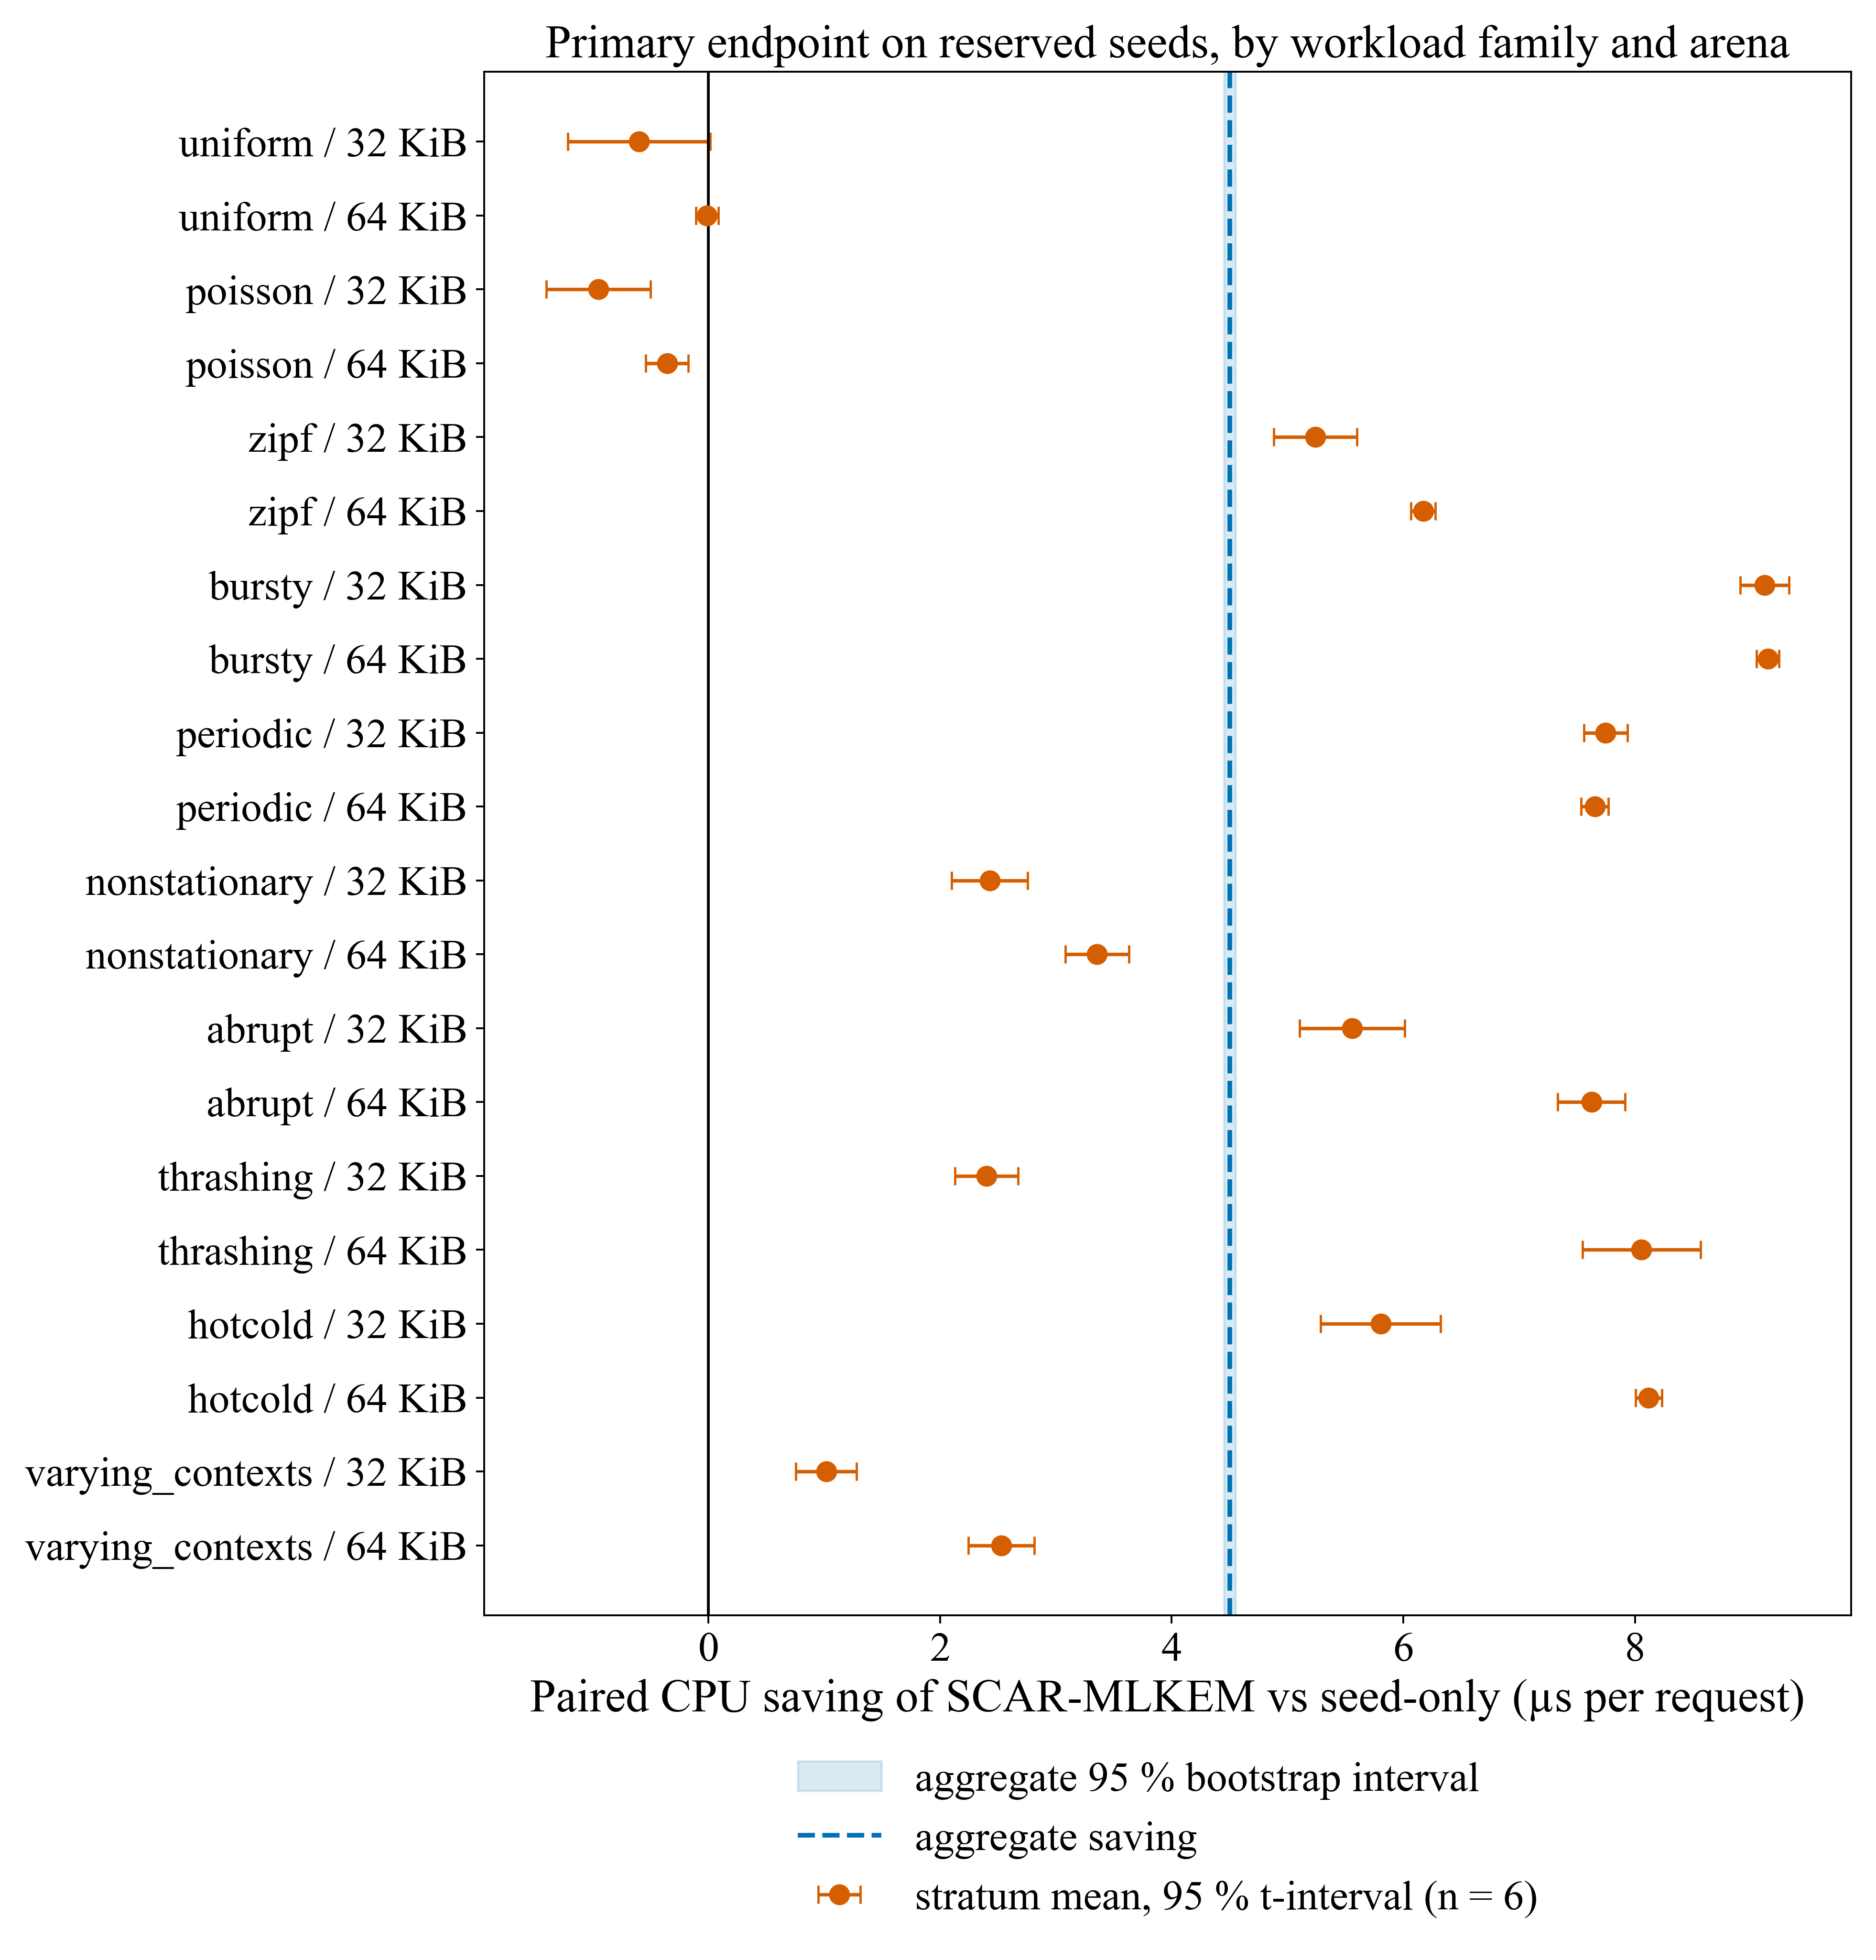

In [5]:
fig, ax = plt.subplots(figsize=(11, 11.5))
y = np.arange(len(per_stratum))[::-1]
ax.errorbar(per_stratum.delta, y, xerr=per_stratum.ci_half, fmt="o", color=COLORS["scar"], ecolor=COLORS["scar"], capsize=4, markersize=8, label="stratum mean, 95 % t-interval (n = 6)")
ax.axvline(0, color="black", linewidth=1.2)
ax.axvspan(lo, hi, color=COLORS["public_s3"], alpha=0.15, label="aggregate 95 % bootstrap interval")
ax.axvline(point, color=COLORS["public_s3"], linewidth=2, linestyle="--", label="aggregate saving")
ax.set_yticks(y); ax.set_yticklabels(per_stratum.index)
ax.set_xlabel("Paired CPU saving of SCAR-MLKEM vs seed-only (µs per request)")
ax.set_title("Primary endpoint on reserved seeds, by workload family and arena")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=1)
check_font_sizes(fig)
save_figure(fig, "primary_forest", per_stratum.rename_axis("Stratum").reset_index())

**Interpretation.** All 720 reserved processes completed with correct shared secrets (720 000 decapsulations) on a board between 49.6 and 52.9 °C without throttling, so no session is excluded. On the primary endpoint the frozen SCAR-MLKEM controller lowers complete request-phase CPU from 38.18 to 33.67 µs per request: an absolute saving of 4.50 µs (95 % bootstrap interval 4.45–4.55 µs) and a relative saving of 11.79 % (11.67–11.92 %), with a one-sided 95 % lower bound of 11.69 %. The saving is positive in 16 of 20 strata and in 99 of 120 sessions. The forest plot shows the structure: bursty, periodic, hot-cold, abrupt and zipf traffic save 5–9 µs per request (14–25 %), nonstationary, thrashing and varying-context traffic 1–8 µs, while uniform and Poisson traffic cost 0.0–1.0 µs more than reconstruction (−0.03 % to −2.5 %), because recurrence inside a 64-context working set with random arrivals is too sparse to repay admissions. The per-stratum t-intervals are narrow (half-widths 0.1–0.6 µs), so the regime pattern is not a sampling artefact. The confirmation reproduces the development estimate (11.56 %) within 0.3 percentage points.

## 4. Secondary comparisons with fixed cache policies

**Question.** Does the adaptive controller lower CPU relative to each strong fixed policy on reserved workloads? **Method.** Paired per session; relative saving as ratio of equal-stratum means with the stratified bootstrap; one-sided paired t-tests over the 120 sessions ($H_1$: SCAR lower), Holm-adjusted across the four comparisons at $\alpha=0.05$. A stratum-level view shows where the controller wins or loses.

In [6]:
sec_rows, pvals = [], []
for p in ["public_s3", "sieve", "lecar", "tiny"]:
    diff = complete[p] - complete["scar"]
    pt, l, h, lb = stratified_bootstrap(diff, complete.stratum, complete[p])
    apt, al, ah, _ = stratified_bootstrap(diff, complete.stratum)
    t_res = stats.ttest_rel(complete[p], complete["scar"], alternative="greater")
    per = (100 * diff / complete[p]).groupby(complete.stratum).mean()
    pvals.append(t_res.pvalue)
    sec_rows.append({"Comparison": f"SCAR-MLKEM vs {LABELS[p]}", "Competitor CPU (µs)": complete.groupby("stratum")[p].mean().mean(),
                     "Absolute saving (µs)": apt, "Absolute 95 % CI (µs)": f"[{al:.3f}, {ah:.3f}]", "Relative saving (%)": pt,
                     "Relative 95 % CI (%)": f"[{l:.3f}, {h:.3f}]", "One-sided 95 % lower bound (%)": lb, "Paired t (df = 119)": t_res.statistic,
                     "p (one-sided)": t_res.pvalue, "Strata where SCAR is lower": int((per > 0).sum()), "Worst stratum (%)": per.min(), "Best stratum (%)": per.max()})
secondary = pd.DataFrame(sec_rows)
ranks = np.argsort(pvals); adjusted = np.empty(len(pvals))
running = 0.0
for k, idx in enumerate(ranks):
    running = max(running, (len(pvals) - k) * pvals[idx]); adjusted[idx] = min(1.0, running)
secondary["Holm-adjusted p"] = adjusted
secondary["Supported at α = 0.05"] = np.where(adjusted < 0.05, "yes", "no")
save_table(secondary[["Comparison", "Competitor CPU (µs)", "Absolute saving (µs)", "Absolute 95 % CI (µs)", "Relative saving (%)", "Relative 95 % CI (%)", "One-sided 95 % lower bound (%)"]], "secondary_effects")
save_table(secondary[["Comparison", "Paired t (df = 119)", "p (one-sided)", "Holm-adjusted p", "Supported at α = 0.05", "Strata where SCAR is lower", "Worst stratum (%)", "Best stratum (%)"]], "secondary_tests")

,Comparison,Competitor CPU (µs),Absolute saving (µs),Absolute 95 % CI (µs),Relative saving (%),Relative 95 % CI (%),One-sided 95 % lower bound (%)
0,SCAR-MLKEM vs Public S3-FIFO,34.151,0.477,"[0.430, 0.523]",1.397,"[1.261, 1.531]",1.282
1,SCAR-MLKEM vs SIEVE,36.314,2.640,"[2.599, 2.680]",7.269,"[7.161, 7.376]",7.177
2,SCAR-MLKEM vs LeCaR,37.208,3.534,"[3.491, 3.576]",9.497,"[9.386, 9.605]",9.405
3,SCAR-MLKEM vs TinyLFU,35.838,2.164,"[2.098, 2.231]",6.038,"[5.861, 6.217]",5.888


,Comparison,Paired t (df = 119),p (one-sided),Holm-adjusted p,Supported at α = 0.05,Strata where SCAR is lower,Worst stratum (%),Best stratum (%)
0,SCAR-MLKEM vs Public S3-FIFO,5.264,3.16e-07,3.16e-07,yes,14,-3.392,7.787
1,SCAR-MLKEM vs SIEVE,7.779,1.47e-12,2.94e-12,yes,18,-3.099,34.458
2,SCAR-MLKEM vs LeCaR,11.753,6.09e-22,1.83e-21,yes,18,-2.646,28.458
3,SCAR-MLKEM vs TinyLFU,14.870,3.29e-29,1.31e-28,yes,20,0.973,14.453


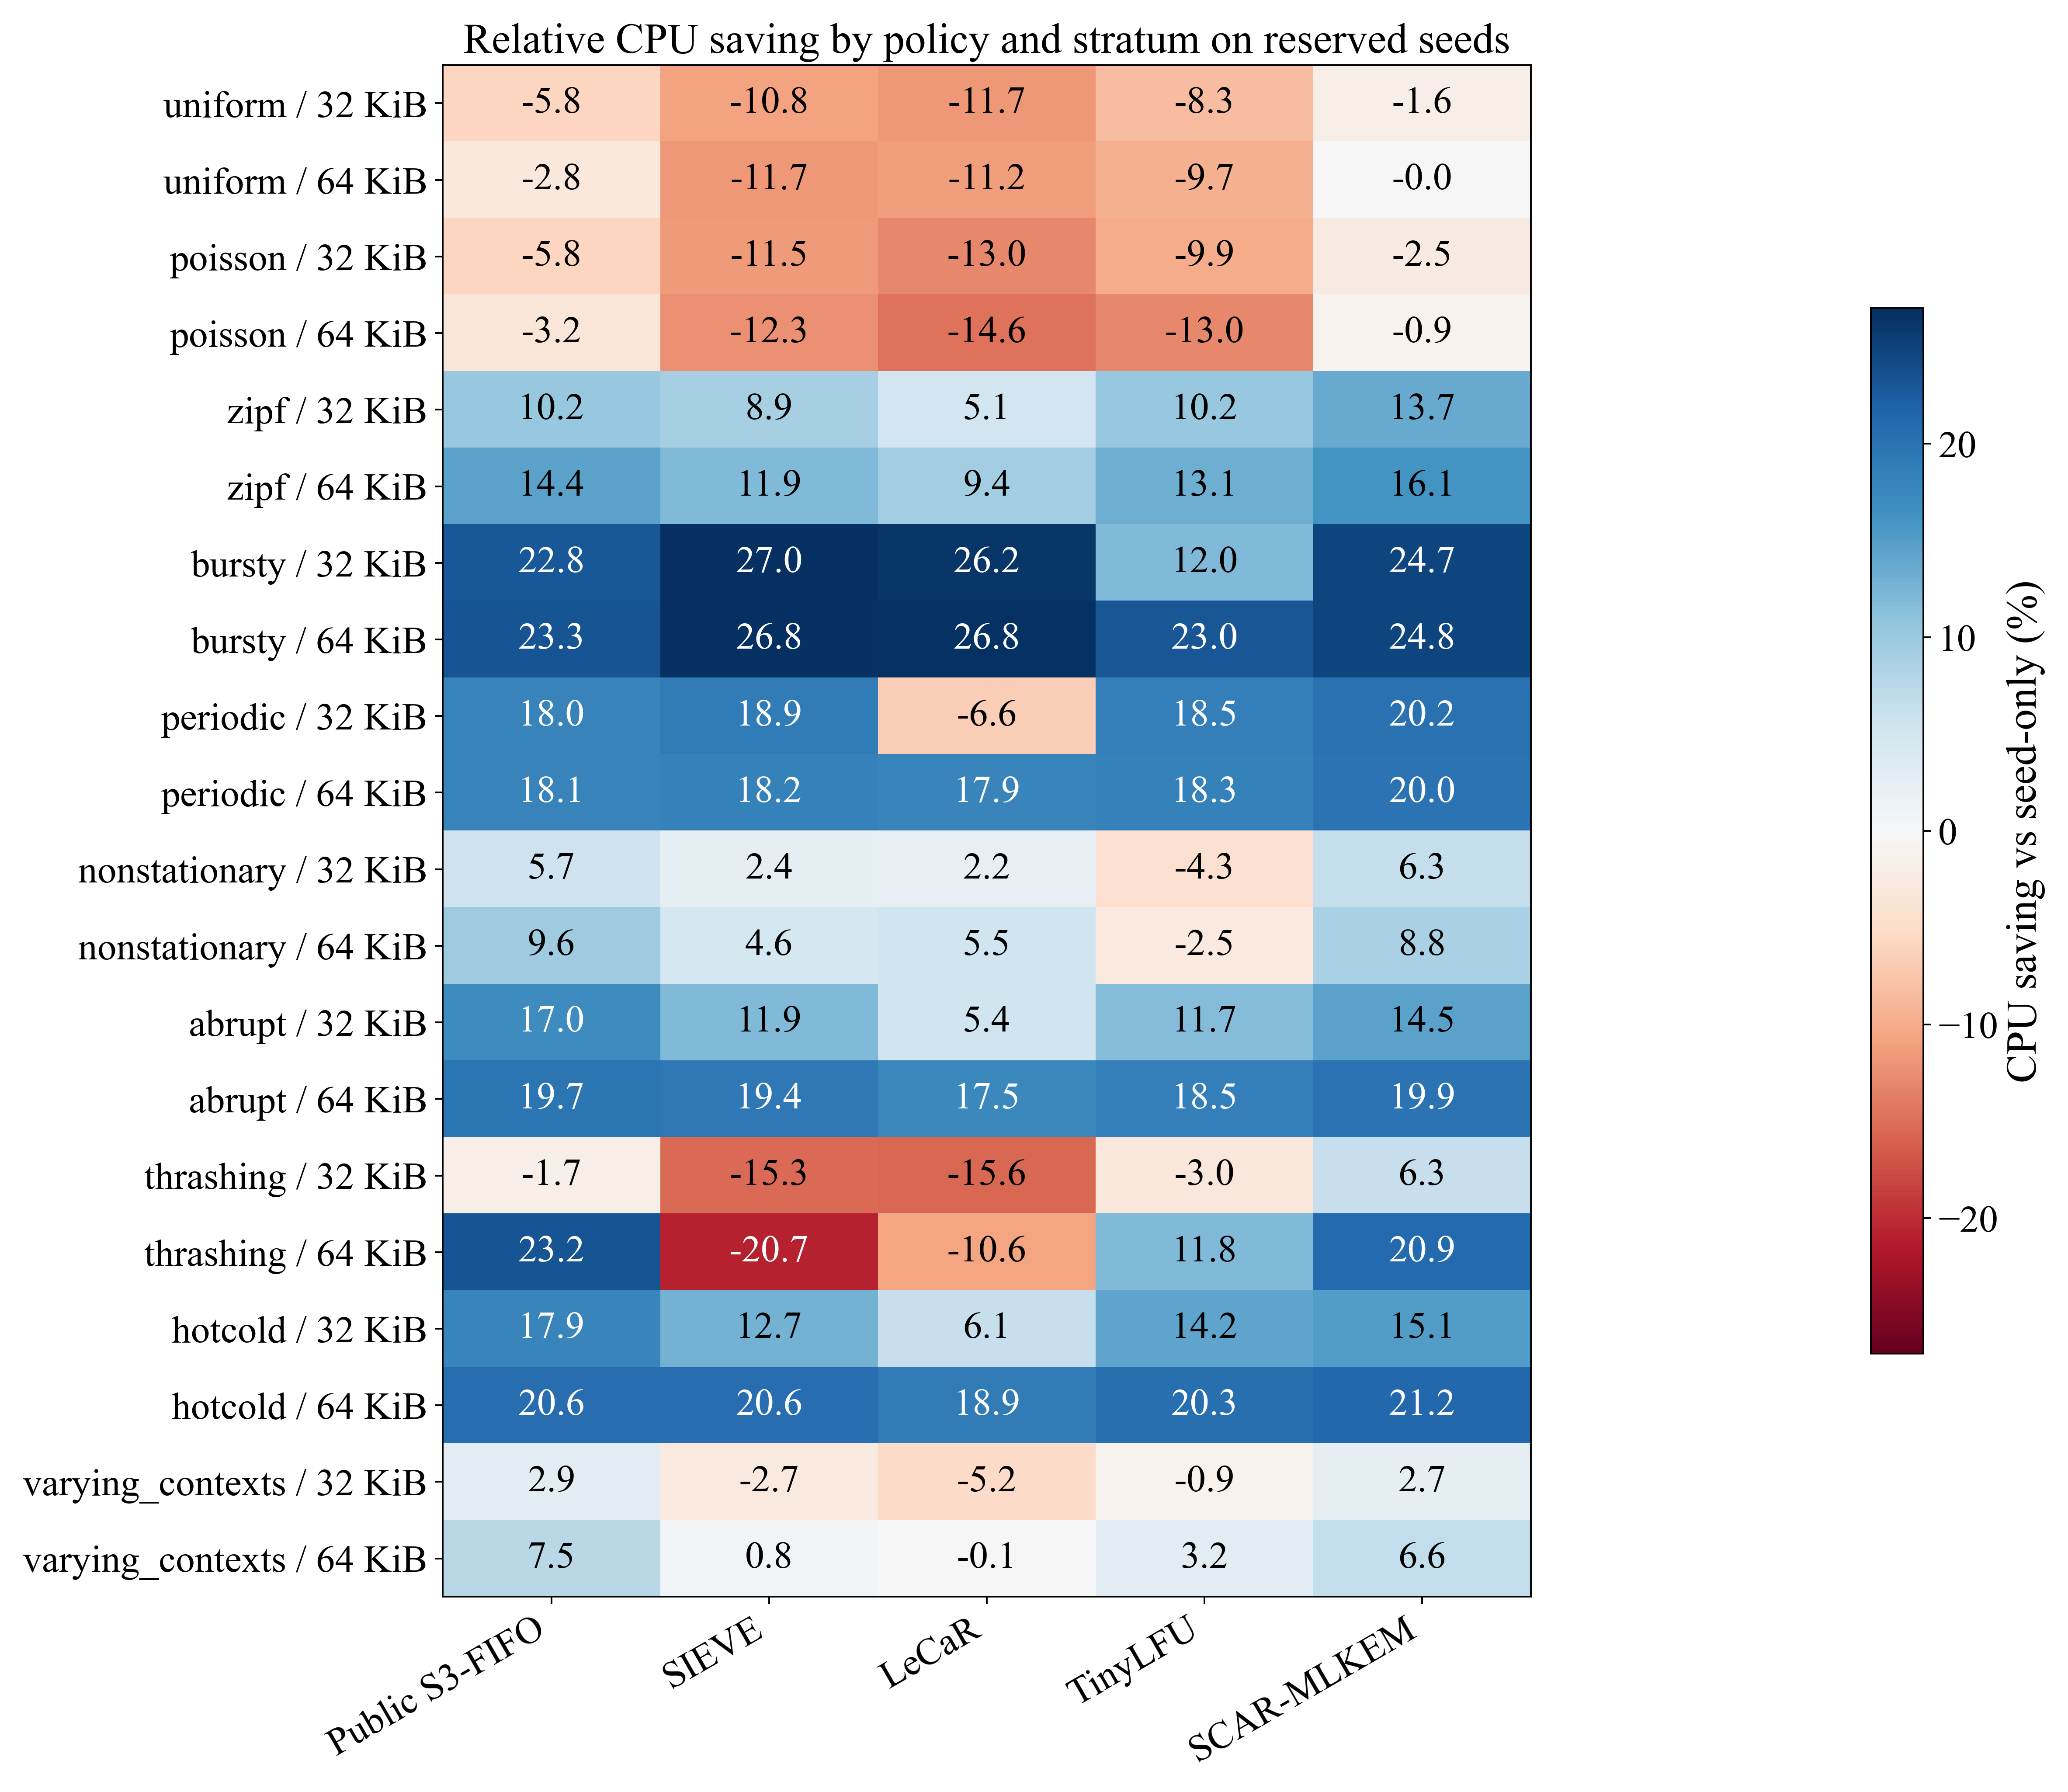

In [7]:
# Regime view: relative CPU of every policy against seed-only per stratum (structure of wins and losses).
rel = complete.groupby("stratum")[POLICIES].mean().loc[order]
rel_pct = rel[POLICIES[1:]].rsub(rel["none"], axis=0).div(rel["none"], axis=0) * 100
fig, ax = plt.subplots(figsize=(13.5, 11.5))
matrix = rel_pct.values
vmax = np.nanmax(np.abs(matrix))
im = ax.imshow(matrix, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(POLICIES) - 1)); ax.set_xticklabels([LABELS[p] for p in POLICIES[1:]], rotation=30, ha="right")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f"{matrix[i, j]:.1f}", ha="center", va="center", fontsize=18, color="white" if abs(matrix[i, j]) > 0.6 * vmax else "black")
fig.colorbar(im, ax=ax, shrink=0.7, label="CPU saving vs seed-only (%)")
ax.set_title("Relative CPU saving by policy and stratum on reserved seeds")
check_font_sizes(fig)
save_figure(fig, "regime_matrix", rel_pct.rename_axis("Stratum").reset_index())

**Interpretation.** All four secondary comparisons are supported after Holm adjustment (largest adjusted $p = 3.2\times10^{-7}$). Against the strongest fixed policy, public S3-FIFO, the adaptive controller saves a further 0.48 µs per request (1.40 %, 95 % interval 1.26–1.53 %, one-sided lower bound 1.28 %), lower in 14 of 20 strata; against SIEVE 7.27 %, LeCaR 9.50 % and TinyLFU 6.04 %, lower in 18, 18 and 20 strata. The regime matrix shows the character of the adaptive increment: it is largest where fixed policies misjudge the working set (thrashing at 32 KiB, +8.0 points over S3-FIFO; uniform and Poisson, where S3-FIFO loses 3–6 % and SCAR-MLKEM loses at most 2.5 %) and negative where a fixed public cache already retains everything (thrashing at 64 KiB, −3.4 points). By the ceiling computed in Notebook 05, the increment over a strong public cache cannot exceed about 4 % at the 10 ms lifetime; the supported claim is a 1.3–1.5 % increment over the best fixed policy and an 11.7–11.9 % saving over the standard implementation.

## 5. Response tails

**Question.** Does retention or decision work worsen p95/p99 response (scheduled arrival to completion)? **Method.** Per-session p95 and p99 of response time; ratio against the seed-only session; median ratio and stratified bootstrap interval of the mean ratio; the distribution of per-session p99 is shown as a figure.

,Policy,p95 ratio vs seed-only (median),p95 ratio mean,p95 ratio 95 % CI,p95 sessions with ratio ≤ 1.05,p99 ratio vs seed-only (median),p99 ratio mean,p99 ratio 95 % CI,p99 sessions with ratio ≤ 1.05
0,Public S3-FIFO,1.044,1.023,"[1.020, 1.025]",79,1.052,1.045,"[1.020, 1.073]",51
1,SIEVE,1.069,1.059,"[1.056, 1.062]",16,1.073,1.057,"[1.037, 1.073]",16
2,LeCaR,1.065,1.050,"[1.047, 1.052]",20,1.067,1.049,"[1.030, 1.065]",19
3,TinyLFU,1.064,1.066,"[1.063, 1.069]",18,1.081,1.085,"[1.056, 1.120]",11
4,SCAR-MLKEM,1.020,1.014,"[1.011, 1.017]",90,1.049,1.030,"[1.011, 1.045]",63


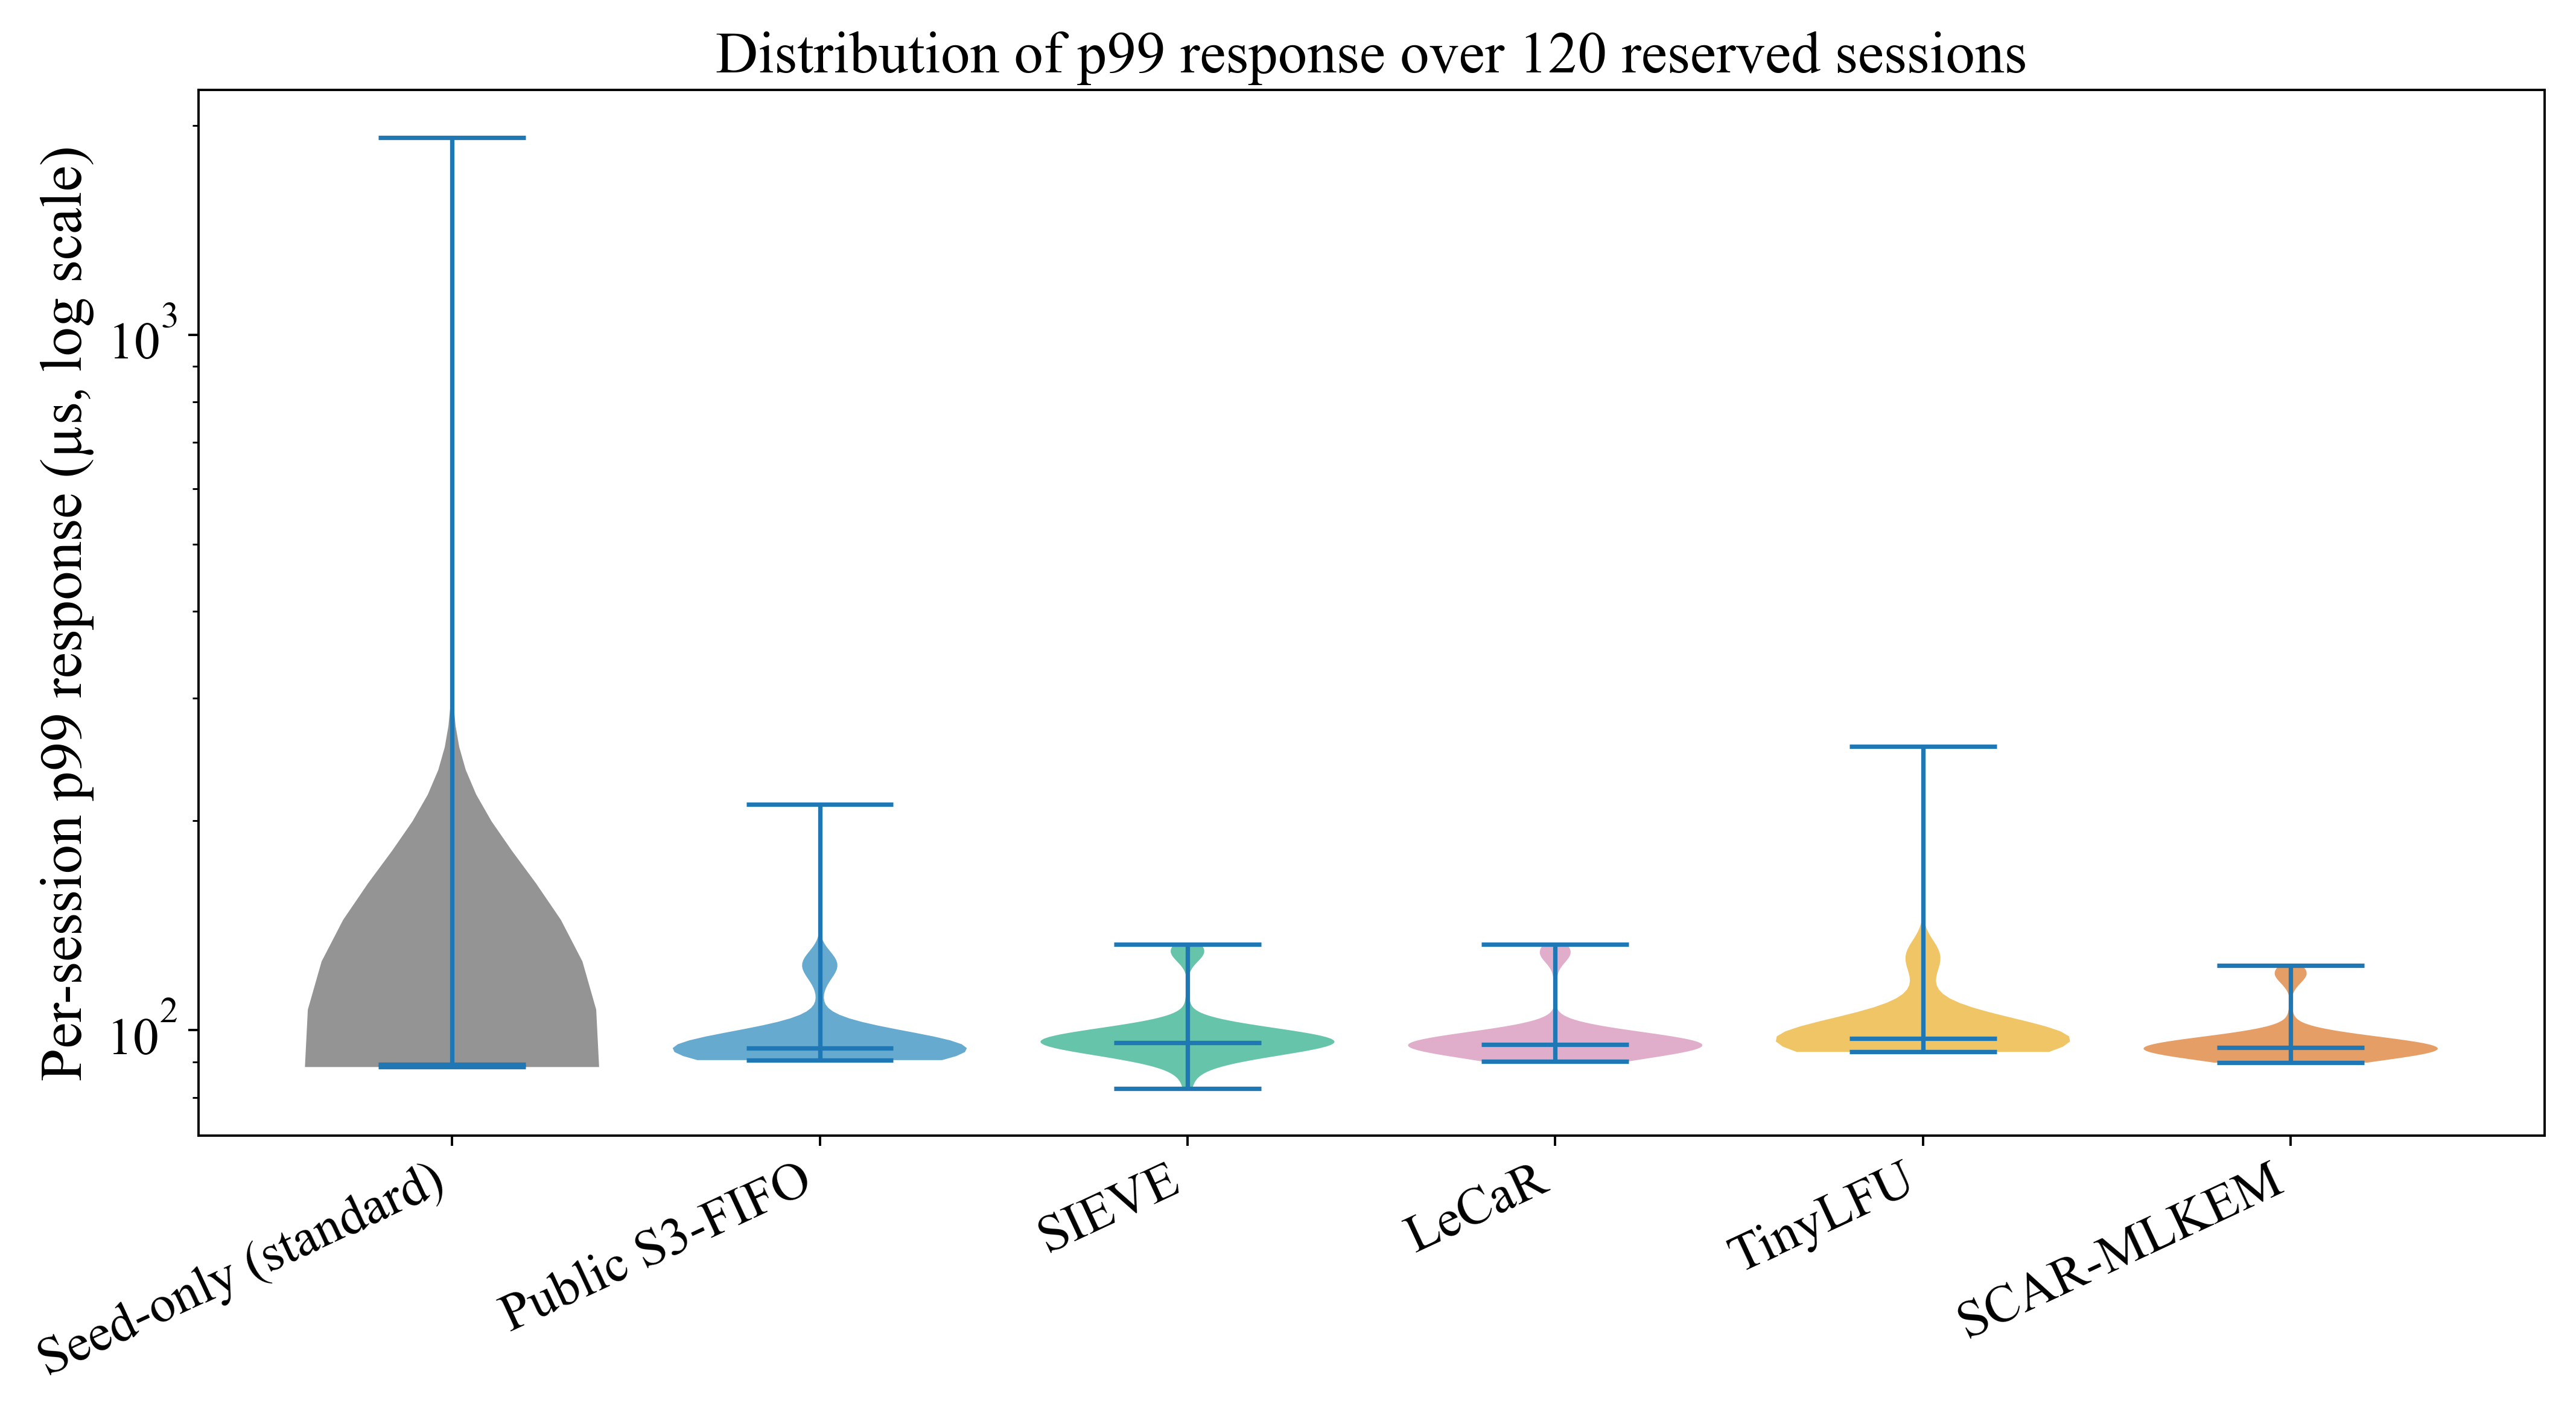

In [8]:
tail_wide = {q: P.pivot_table(index=["stratum", "seed", "arena_bytes"], columns="setting", values=f"response_{q}_us").rename_axis(columns=None) for q in ("p95", "p99")}
tail_rows = []
for p in POLICIES[1:]:
    row = {"Policy": LABELS[p]}
    for q in ("p95", "p99"):
        ratio = (tail_wide[q][p] / tail_wide[q]["none"]).dropna()
        pt, l, h, _ = stratified_bootstrap(ratio, ratio.index.get_level_values("stratum"))
        row.update({f"{q} ratio vs seed-only (median)": ratio.median(), f"{q} ratio mean": pt, f"{q} ratio 95 % CI": f"[{l:.3f}, {h:.3f}]",
                    f"{q} sessions with ratio ≤ 1.05": int((ratio <= 1.05).sum())})
    tail_rows.append(row)
save_table(pd.DataFrame(tail_rows), "response_tails")
fig, ax = plt.subplots(figsize=(12, 6.5))
data = [P[P.setting == p].response_p99_us.values for p in POLICIES]
parts = ax.violinplot(data, positions=range(len(POLICIES)), showmedians=True, widths=0.8)
for body, p in zip(parts["bodies"], POLICIES):
    body.set_facecolor(COLORS[p]); body.set_alpha(0.6)
ax.set_xticks(range(len(POLICIES))); ax.set_xticklabels([LABELS[p] for p in POLICIES], rotation=25, ha="right")
ax.set_yscale("log"); ax.set_ylabel("Per-session p99 response (µs, log scale)"); ax.set_title("Distribution of p99 response over 120 reserved sessions")
check_font_sizes(fig)
save_figure(fig, "p99_distribution", P[["session_id", "setting", "response_p95_us", "response_p99_us"]])

**Interpretation.** SCAR-MLKEM has the smallest tail penalty of all retaining policies: the median per-session p95 ratio against seed-only is 1.020 (mean 1.014, interval 1.011–1.017) and the median p99 ratio 1.049 (mean 1.030, 1.011–1.045); 90 of 120 sessions stay within a 1.05 p95 ratio and 63 within a 1.05 p99 ratio. Public S3-FIFO sits at 1.044 and 1.052, SIEVE, LeCaR and TinyLFU at 1.06–1.08, with TinyLFU's p99 interval reaching 1.12. The distribution figure shows that the seed-only baseline itself has one session with a p99 of about 1.9 ms, an operating-system stall unrelated to the policy; retention does not create such outliers. The tail cost of retention is a few percent of a 90 µs p95, and the controller's decision work does not add to it.

## 6. Memory and secret-lifetime discipline

**Question.** What memory does each policy occupy, and were retained secrets always cleared within the 10 ms limit? **Method.** Native metadata per process: peak RSS, retained locked mapping, peak arena occupancy and policy metadata; lifecycle endpoints (late clears, maximum lateness, maximum residency, zeroizations). The figure shows the empirical distribution of the maximum secret residency per session for the secret-retaining policies.

,Policy,Peak RSS (MiB),Retained locked mapping (KiB),Peak arena occupancy (KiB) 32 KiB,Peak arena occupancy (KiB) 64 KiB,Policy metadata (bytes)
0,Seed-only (standard),21.816,128.000,1.469,1.594,0.000
1,Public S3-FIFO,21.832,128.000,29.875,61.906,624.000
2,SIEVE,21.853,128.000,31.945,63.666,32.000
3,LeCaR,21.870,128.000,30.105,50.549,2496.000
4,TinyLFU,21.882,128.000,31.933,63.598,1184.000
5,SCAR-MLKEM,21.886,128.000,31.183,58.185,1824.000


,Policy,Sessions,Secret hit (%),Zeroizations per session,Max secret residency (ms),Sessions with a late clear,Late clears,Max lateness (µs)
0,Seed-only (standard),120,0.000,0.000,0.000,0,0,0.000
1,Public S3-FIFO,120,0.000,0.000,0.000,0,0,0.000
2,SIEVE,120,36.339,633.575,9.600,0,0,0.000
3,LeCaR,120,45.000,544.875,10.015,1,1,15.370
4,TinyLFU,120,40.076,367.367,10.566,2,3,565.630
5,SCAR-MLKEM,120,32.712,168.625,9.905,0,0,0.000


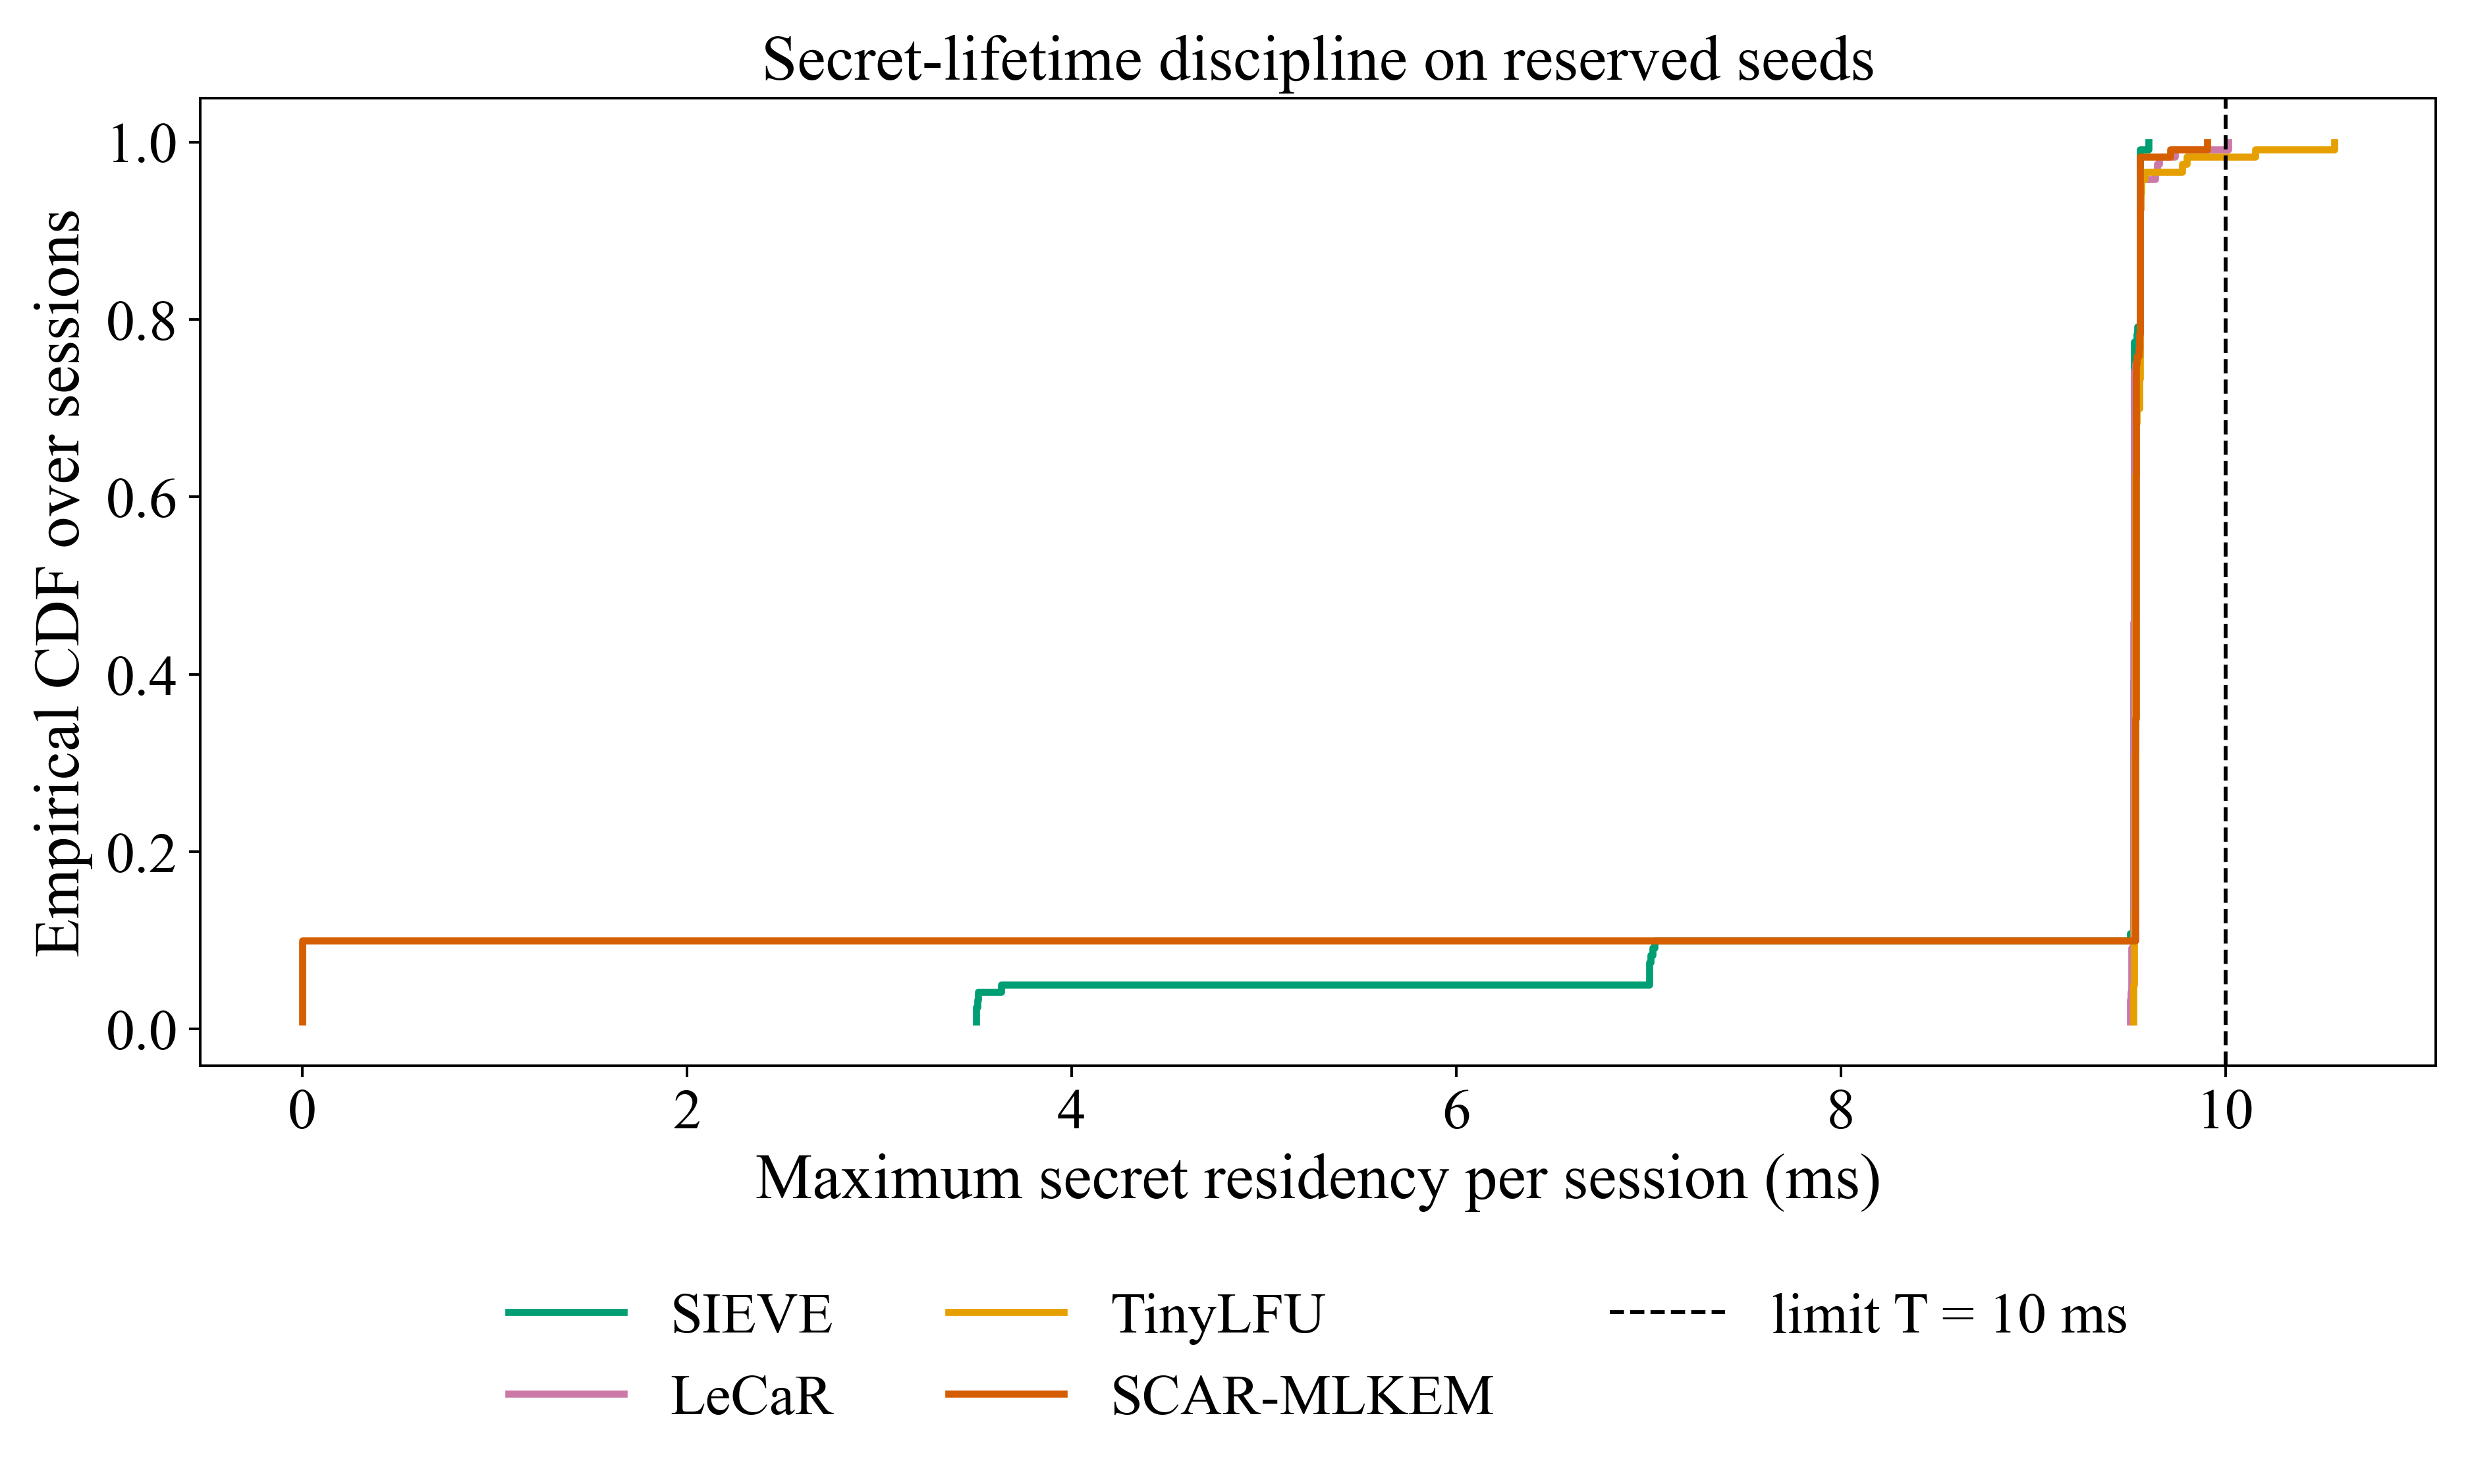

In [9]:
mem_rows = []
for p in POLICIES:
    g = P[P.setting == p]
    mem_rows.append({"Policy": LABELS[p], "Peak RSS (MiB)": g.peak_rss_bytes.mean() / 2**20, "Retained locked mapping (KiB)": g.retained_mapping_bytes.mean() / 1024,
                     "Peak arena occupancy (KiB) 32 KiB": g[g.arena_bytes == 32768].peak_occupied_bytes.mean() / 1024,
                     "Peak arena occupancy (KiB) 64 KiB": g[g.arena_bytes == 65536].peak_occupied_bytes.mean() / 1024,
                     "Policy metadata (bytes)": g.policy_bytes.mean()})
save_table(pd.DataFrame(mem_rows), "memory")
life_rows = []
for p in POLICIES:
    g = P[P.setting == p]
    life_rows.append({"Policy": LABELS[p], "Sessions": len(g), "Secret hit (%)": 100 * g.secret_hit.mean(), "Zeroizations per session": g.zeroizations.mean(),
                      "Max secret residency (ms)": g.secret_max_residency_ms.max(), "Sessions with a late clear": int((g.late_clear_count > 0).sum()),
                      "Late clears": int(g.late_clear_count.sum()), "Max lateness (µs)": g.max_lateness_us.max()})
save_table(pd.DataFrame(life_rows), "lifecycle")
fig, ax = plt.subplots(figsize=(10.5, 6.2))
for p in ["sieve", "lecar", "tiny", "scar"]:
    values = np.sort(P[P.setting == p].secret_max_residency_ms.values)
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=COLORS[p], linewidth=2.2, label=LABELS[p])
ax.axvline(FREEZE["ttl_ms"], color="black", linestyle="--", linewidth=1.2, label=f"limit T = {FREEZE['ttl_ms']} ms")
ax.set_xlabel("Maximum secret residency per session (ms)"); ax.set_ylabel("Empirical CDF over sessions")
ax.set_title("Secret-lifetime discipline on reserved seeds")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
check_font_sizes(fig)
save_figure(fig, "residency_ecdf", P[P.setting.isin(["sieve", "lecar", "tiny", "scar"])][["session_id", "setting", "secret_max_residency_ms", "late_clear_count", "max_lateness_us"]])

**Interpretation.** Memory is bounded by construction and flat across policies: peak RSS is 21.82–21.89 MiB for every policy, the retained locked mapping is 128 KiB, and the arenas are used up to 31 KiB of 32 KiB and 58 KiB of 64 KiB by SCAR-MLKEM (62 KiB by S3-FIFO, which never retains secrets). Policy metadata is 1.8 KiB for SCAR-MLKEM against 2.5 KiB for LeCaR and 0.6 KiB for S3-FIFO. Lifecycle discipline held for the frozen method: SCAR-MLKEM recorded no late clear in 120 sessions with a maximum residency of 9.90 ms against the 10 ms limit, while performing 169 checked zeroizations per session (fewer than SIEVE's 634, because conditional admission retains fewer secrets). SIEVE also recorded none; LeCaR one late clear of 15 µs and TinyLFU three late clears in two sessions with a maximum lateness of 566 µs. The ECDF shows that about 10 % of SCAR sessions never retained a secret (uniform, Poisson and thrashing at 32 KiB) and that the remaining sessions cluster just below the limit, where the guard releases entries. These four late clears across 720 processes quantify the operating-system limit that no guard removes; they are reported, not gated.

## 7. Computational efficiency and controller overhead

**Question.** What does the controller itself cost, and what throughput does the complete path sustain? **Method.** Mean instrumented planning region, complete CPU, scheduled wall time per request and process wall time per policy (descriptive; wall regions include instrumentation).

In [10]:
eff = P.groupby("setting").agg(cpu=("cpu_us", "mean"), planning=("planning_ns", "mean"), reconstruction=("reconstruction_ns", "mean"),
                               decapsulation=("decapsulation_ns", "mean"), public_prepare=("public_prepare_ns", "mean"),
                               service_p50=("service_p50_us", "mean"), wall=("wall_seconds", "mean")).loc[POLICIES]
efficiency = pd.DataFrame({"Policy": [LABELS[p] for p in POLICIES], "Complete CPU (µs/request)": eff.cpu, "Planning (µs)": eff.planning / 1000,
    "Reconstruction (µs)": eff.reconstruction / 1000, "Decapsulation (µs)": eff.decapsulation / 1000, "Public preparation (µs)": eff.public_prepare / 1000,
    "Service median (µs)": eff.service_p50, "Requests per CPU-second": 1e6 / eff.cpu, "Process wall (s)": eff.wall})
save_table(efficiency, "efficiency")

,Policy,Complete CPU (µs/request),Planning (µs),Reconstruction (µs),Decapsulation (µs),Public preparation (µs),Service median (µs),Requests per CPU-second,Process wall (s)
0,Seed-only (standard),38.177,0.068,3.266,28.858,0.000,34.356,26193.730,0.596
1,Public S3-FIFO,34.151,0.465,3.255,19.790,3.837,29.869,29281.481,0.565
2,SIEVE,36.314,1.121,2.116,19.790,4.817,31.734,27537.806,0.600
3,LeCaR,37.208,0.844,1.847,19.787,6.127,33.764,26876.023,0.564
4,TinyLFU,35.838,1.933,2.032,23.833,0.393,31.495,27903.400,0.598
5,SCAR-MLKEM,33.674,0.467,2.255,23.132,0.423,29.180,29696.327,0.564


**Interpretation.** The controller's decision work costs 0.47 µs per request, the same as public S3-FIFO's bookkeeping (0.47 µs) and far below TinyLFU (1.93 µs) or SIEVE (1.12 µs). Complete CPU per request falls from 38.18 to 33.67 µs, which raises sustainable throughput on the pinned core from 26 194 to 29 696 requests per CPU-second (+13.4 %). The instrumented stage regions are wall-clock and overlap differently between policies (SCAR-MLKEM constructs retained public matrices inside its decapsulation region, S3-FIFO in a separate preparation region), so they describe where time is spent, not an additive CPU budget. Process wall time per 1000-request session is 0.56–0.60 s for every policy because the schedule, not the computation, dominates elapsed time.

## 8. Robustness across arenas and families

**Question.** Is the primary effect stable across the two memory budgets and across families, and where does the adaptive controller lose against the best fixed policy? **Method.** Primary saving by arena with bootstrap intervals; per family the best fixed policy on reserved data and SCAR's paired difference to it (exploratory, not a new selection).

In [11]:
arena_rows = []
for arena in ARENAS:
    g = complete[complete.arena_bytes == arena]
    pt, l, h, lb = stratified_bootstrap(g.delta_scar, g.stratum, g["none"])
    apt, al, ah, _ = stratified_bootstrap(g.delta_scar, g.stratum)
    arena_rows.append({"Arena": f"{arena // 1024} KiB", "Sessions": len(g), "Absolute saving vs seed-only (µs)": apt, "Absolute 95 % CI (µs)": f"[{al:.3f}, {ah:.3f}]",
                       "Relative saving (%)": pt, "Relative 95 % CI (%)": f"[{l:.3f}, {h:.3f}]", "One-sided 95 % lower bound (%)": lb})
save_table(pd.DataFrame(arena_rows), "robustness_by_arena")
fam_rows = []
for family in FAMILIES:
    g = complete[complete.family == family]
    means = g[POLICIES[1:-1]].mean(); best = means.idxmin()
    d = g[best] - g["scar"]
    t_res = stats.ttest_rel(g[best], g["scar"])
    fam_rows.append({"Family": family, "Seed-only (µs)": g["none"].mean(), "SCAR-MLKEM (µs)": g["scar"].mean(), "Saving vs seed-only (%)": 100 * (g["none"] - g["scar"]).mean() / g["none"].mean(),
                     "Best fixed policy": LABELS[best], "Best fixed (µs)": means[best], "SCAR − best fixed (µs)": -d.mean(), "Paired t p (two-sided, n = 12)": t_res.pvalue})
save_table(pd.DataFrame(fam_rows), "robustness_by_family")

,Arena,Sessions,Absolute saving vs seed-only (µs),Absolute 95 % CI (µs),Relative saving (%),Relative 95 % CI (%),One-sided 95 % lower bound (%)
0,32 KiB,60,3.777,"[3.691, 3.861]",9.891,"[9.674, 10.101]",9.706
1,64 KiB,60,5.229,"[5.176, 5.282]",13.699,"[13.568, 13.831]",13.589


,Family,Seed-only (µs),SCAR-MLKEM (µs),Saving vs seed-only (%),Best fixed policy,Best fixed (µs),SCAR − best fixed (µs),"Paired t p (two-sided, n = 12)"
0,uniform,38.492,38.798,-0.794,Public S3-FIFO,40.148,-1.351,1.42e-06
1,poisson,37.862,38.516,-1.728,Public S3-FIFO,39.574,-1.057,2.27e-06
2,zipf,38.399,32.693,14.859,Public S3-FIFO,33.675,-0.982,2.32e-05
3,bursty,36.876,27.742,24.770,SIEVE,26.955,0.787,6.05e-10
4,periodic,38.288,30.588,20.112,SIEVE,31.200,-0.612,3.00e-09
5,nonstationary,38.289,35.397,7.554,Public S3-FIFO,35.371,0.026,0.789
6,abrupt,38.381,31.790,17.173,Public S3-FIFO,31.346,0.444,0.019
7,thrashing,38.466,33.237,13.595,Public S3-FIFO,34.301,-1.065,0.102
8,hotcold,38.399,31.437,18.131,Public S3-FIFO,31.015,0.422,0.076
9,varying_contexts,38.318,36.545,4.627,Public S3-FIFO,36.329,0.216,0.043


**Interpretation.** The primary effect holds at both memory budgets: 9.89 % (9.67–10.10 %) at 32 KiB and 13.70 % (13.57–13.83 %) at 64 KiB, so a larger arena roughly adds four points by holding more public records. By family, SCAR-MLKEM saves 14–25 % on zipf, bursty, periodic, abrupt and hot-cold traffic, 5–14 % on nonstationary, thrashing and varying-context traffic, and loses 0.8 % (uniform) and 1.7 % (Poisson). Against the best fixed policy chosen per family in hindsight, the controller is lower in uniform, Poisson, zipf and periodic traffic (paired two-sided $p<10^{-4}$), statistically indistinguishable in nonstationary, thrashing and hot-cold traffic, and higher by 0.2–0.8 µs in bursty, abrupt and varying-context traffic, where SIEVE or S3-FIFO retain the recurring set as well as the forecast does. This hindsight selection is exploratory: it conditions on test outcomes and is not a deployable rule. The practical reading is that SCAR-MLKEM is never far from the best fixed policy and is the only policy that avoids large losses in every regime.

## 9. Supplementary robustness campaigns on the same board

**Question.** Does the primary effect survive (a) an independent replication on a second set of reserved seeds, (b) a lower CPU frequency that emulates a weaker device, (c) interference from busy neighbouring cores, and (d) real-time scheduling of the responder, which isolates the operating-system share of late secret clears? **Design (fixed before acquisition, after the primary analysis above).** Four campaigns with the frozen method and the same worker: replication, 720 processes on 60 new reserved seeds (namespace 7 100 000); frequency, 240 processes at a pinned 1.5 GHz under the `userspace` governor (seeds 7 200 000, two per stratum); interference, 240 processes with one busy loop pinned to each of the other three cores (seeds 7 300 000); real-time, 160 processes of the four secret-retaining policies launched under `SCHED_FIFO` priority 10 (seeds 7 400 000). These are supplementary checks: they are reported with the same estimators but do not replace the prespecified primary result.

In [21]:
SUPP = {}
def supp_seeds(base, per_family):
    return {family: [base + 10 * i + r for r in range(per_family)] for i, family in enumerate(FAMILIES)}
main_settings = [dict(name=p, policy=p, components=SCAR_MASK if p == "scar" else 31, ttl_ms=10) for p in POLICIES]
secret_settings = [s for s in main_settings if s["name"] in ("sieve", "lecar", "tiny", "scar")]
designs = {
    "replication": dict(identity="replication_20261020", seeds=supp_seeds(7_100_000, 6), settings=main_settings, extra=dict(costs_ns=COSTS, purpose="within-device replication")),
    "frequency": dict(identity="frequency1500_20261020", seeds=supp_seeds(7_200_000, 2), settings=main_settings,
                      extra=dict(costs_ns=COSTS, purpose="pinned 1.5 GHz", governor="userspace", frequency_khz=1_500_000)),
    "interference": dict(identity="interference_20261020", seeds=supp_seeds(7_300_000, 2), settings=main_settings, extra=dict(costs_ns=COSTS, purpose="busy loops on cores 0, 1, 3")),
    "realtime": dict(identity="realtime_20261020", seeds=supp_seeds(7_400_000, 2), settings=secret_settings, extra=dict(costs_ns=COSTS, purpose="SCHED_FIFO priority 10 for the responder")),
}
for key, d in designs.items():
    used = registered_seeds(exclude=MANIFESTS / "Supplementary06" / d["identity"])
    assert not used.intersection(s for v in d["seeds"].values() for s in v), key
    plan = campaign_plan_rows(FAMILIES, d["seeds"], ARENAS, d["settings"], "test")
    reg, spec = register_campaign("Supplementary06", d["identity"], plan, split="test", native=NATIVE, extra=d["extra"])
    SUPP[key] = dict(reg=reg, spec=spec, plan=plan)
design_table = pd.DataFrame([dict(Campaign=k, Processes=len(v["plan"]), Policies=len({r["setting"] for r in v["plan"]}), Seeds=sum(len(s) for s in designs[k]["seeds"].values()),
                                  Condition=designs[k]["extra"]["purpose"]) for k, v in SUPP.items()])
save_table(design_table, "supplementary_design")

,Campaign,Processes,Policies,Seeds,Condition
0,replication,720,6,60,within-device replication
1,frequency,240,6,20,pinned 1.5 GHz
2,interference,240,6,20,"busy loops on cores 0, 1, 3"
3,realtime,160,4,20,SCHED_FIFO priority 10 for the responder


In [22]:
supp_done, supp_frames = {}, {}
supp_done["replication"] = run_campaign(SUPP["replication"]["reg"], SUPP["replication"]["spec"])
supp_done["frequency"] = run_campaign(SUPP["frequency"]["reg"], SUPP["frequency"]["spec"])
supp_done["interference"] = run_campaign(SUPP["interference"]["reg"], SUPP["interference"]["spec"],
                                         prepare=lambda: pi_background_load([0, 1, 3]), finish=pi_stop_background_load)
supp_done["realtime"] = run_campaign(SUPP["realtime"]["reg"], SUPP["realtime"]["spec"], launch_prefix="chrt -f 10 ", as_root=True)
for key in SUPP:
    frame = load_campaign(SUPP[key]["spec"], supp_done[key]); frame["campaign"] = key; supp_frames[key] = frame
    frame.to_csv(INTERIM / f"06_supplementary_{key}.csv", index=False)
coverage = pd.DataFrame([dict(Campaign=k, Processes=len(f), Passed=int(f.status.eq("passed").sum()), Failed=int(f.status.ne("passed").sum()),
                              **{"Mean frequency (MHz)": f.frequency_mhz.mean(), "Scheduler (0 = other, 1 = FIFO)": int(f.scheduler.max()),
                                 "Late secret clears": int(f.late_clear_count.fillna(0).sum()), "Board temperature (°C) max": f.temperature_c.max(),
                                 "Wall time (min)": f.wall_seconds.sum() / 60}) for k, f in supp_frames.items()])
save_table(coverage, "supplementary_coverage")

,Campaign,Processes,Passed,Failed,Mean frequency (MHz),"Scheduler (0 = other, 1 = FIFO)",Late secret clears,Board temperature (°C) max,Wall time (min)
0,replication,720,720,0,2400.000,0,19,53.450,6.973
1,frequency,240,240,0,1500.000,0,0,50.150,2.365
2,interference,240,240,0,2400.000,0,31,68.300,2.293
3,realtime,160,160,0,2400.000,1,0,55.100,1.548


In [23]:
# Primary and S3-FIFO contrasts under each condition, same estimators as Sections 3 and 4.
def primary_rows(frame, label):
    P2 = frame[frame.status.eq("passed")]
    w = P2.pivot_table(index=["stratum", "family", "arena_bytes", "seed"], columns="setting", values="cpu_us").reset_index().rename_axis(columns=None)
    w = w.dropna(subset=["none", "scar"]).copy()
    pt, lo, hi, lb = stratified_bootstrap(w["none"] - w["scar"], w.stratum, w["none"])
    row = {"Condition": label, "Sessions": len(w), "Seed-only CPU (µs)": w.groupby("stratum")["none"].mean().mean(), "SCAR-MLKEM CPU (µs)": w.groupby("stratum")["scar"].mean().mean(),
           "Saving vs seed-only (%)": pt, "95 % CI (%)": f"[{lo:.3f}, {hi:.3f}]", "Lower bound (%)": lb}
    if "public_s3" in w.columns:
        pt2, lo2, hi2, _ = stratified_bootstrap(w["public_s3"] - w["scar"], w.stratum, w["public_s3"])
        row.update({"Saving vs S3-FIFO (%)": pt2, "95 % CI vs S3-FIFO (%)": f"[{lo2:.3f}, {hi2:.3f}]"})
    return row
condition_rows = [primary_rows(test, "Primary confirmation (2.4 GHz, performance)"),
                  primary_rows(supp_frames["replication"], "Replication, new reserved seeds"),
                  primary_rows(supp_frames["frequency"], "Pinned 1.5 GHz"),
                  primary_rows(supp_frames["interference"], "Busy loops on three other cores")]
save_table(pd.DataFrame(condition_rows), "supplementary_primary_by_condition")

,Condition,Sessions,Seed-only CPU (µs),SCAR-MLKEM CPU (µs),Saving vs seed-only (%),95 % CI (%),Lower bound (%),Saving vs S3-FIFO (%),95 % CI vs S3-FIFO (%)
0,"Primary confirmation (2.4 GHz, performance)",120,38.177,33.674,11.795,"[11.671, 11.920]",11.689,1.397,"[1.261, 1.531]"
1,"Replication, new reserved seeds",120,38.197,33.716,11.731,"[11.569, 11.876]",11.596,1.252,"[1.071, 1.415]"
2,Pinned 1.5 GHz,40,60.806,53.655,11.761,"[11.616, 11.907]",11.637,1.728,"[1.544, 1.918]"
3,Busy loops on three other cores,40,38.146,33.752,11.518,"[11.343, 11.693]",11.365,1.112,"[0.770, 1.448]"


In [24]:
# Lifecycle and tails under real-time scheduling against the default scheduler (same four policies, test seeds).
def lifecycle_rows(frame, label):
    rows = []
    for p in ["sieve", "lecar", "tiny", "scar"]:
        g = frame[(frame.setting == p) & frame.status.eq("passed")]
        rows.append({"Condition": label, "Policy": LABELS[p], "Sessions": len(g), "Late clears": int(g.late_clear_count.sum()),
                     "Sessions with a late clear": int((g.late_clear_count > 0).sum()), "Max lateness (µs)": g.max_lateness_us.max(),
                     "Max residency (ms)": g.secret_max_residency_ms.max(), "Response p99 (µs)": g.response_p99_us.mean(), "Complete CPU (µs)": g.cpu_us.mean()})
    return rows
rt_table = pd.DataFrame(lifecycle_rows(test, "Default scheduler (primary, 6 seeds)") + lifecycle_rows(supp_frames["interference"], "Busy neighbours (2 seeds)") + lifecycle_rows(supp_frames["realtime"], "SCHED_FIFO 10 (2 seeds)"))
save_table(rt_table, "supplementary_lifecycle_by_condition")

,Condition,Policy,Sessions,Late clears,Sessions with a late clear,Max lateness (µs),Max residency (ms),Response p99 (µs),Complete CPU (µs)
0,"Default scheduler (primary, 6 seeds)",SIEVE,120,0,0,0.000,9.600,99.409,36.314
1,"Default scheduler (primary, 6 seeds)",LeCaR,120,1,1,15.370,10.015,98.687,37.208
2,"Default scheduler (primary, 6 seeds)",TinyLFU,120,3,2,565.630,10.566,101.928,35.838
3,"Default scheduler (primary, 6 seeds)",SCAR-MLKEM,120,0,0,0.000,9.905,96.810,33.674
4,Busy neighbours (2 seeds),SIEVE,40,1,1,37.870,10.038,140.790,36.341
5,Busy neighbours (2 seeds),LeCaR,40,15,4,4607.963,14.608,149.252,37.177
6,Busy neighbours (2 seeds),TinyLFU,40,5,5,42.722,10.043,101.500,35.747
7,Busy neighbours (2 seeds),SCAR-MLKEM,40,10,3,3354.740,13.355,160.681,33.752
8,SCHED_FIFO 10 (2 seeds),SIEVE,40,0,0,0.000,9.524,48.774,35.819
9,SCHED_FIFO 10 (2 seeds),LeCaR,40,0,0,0.000,9.524,49.318,36.789


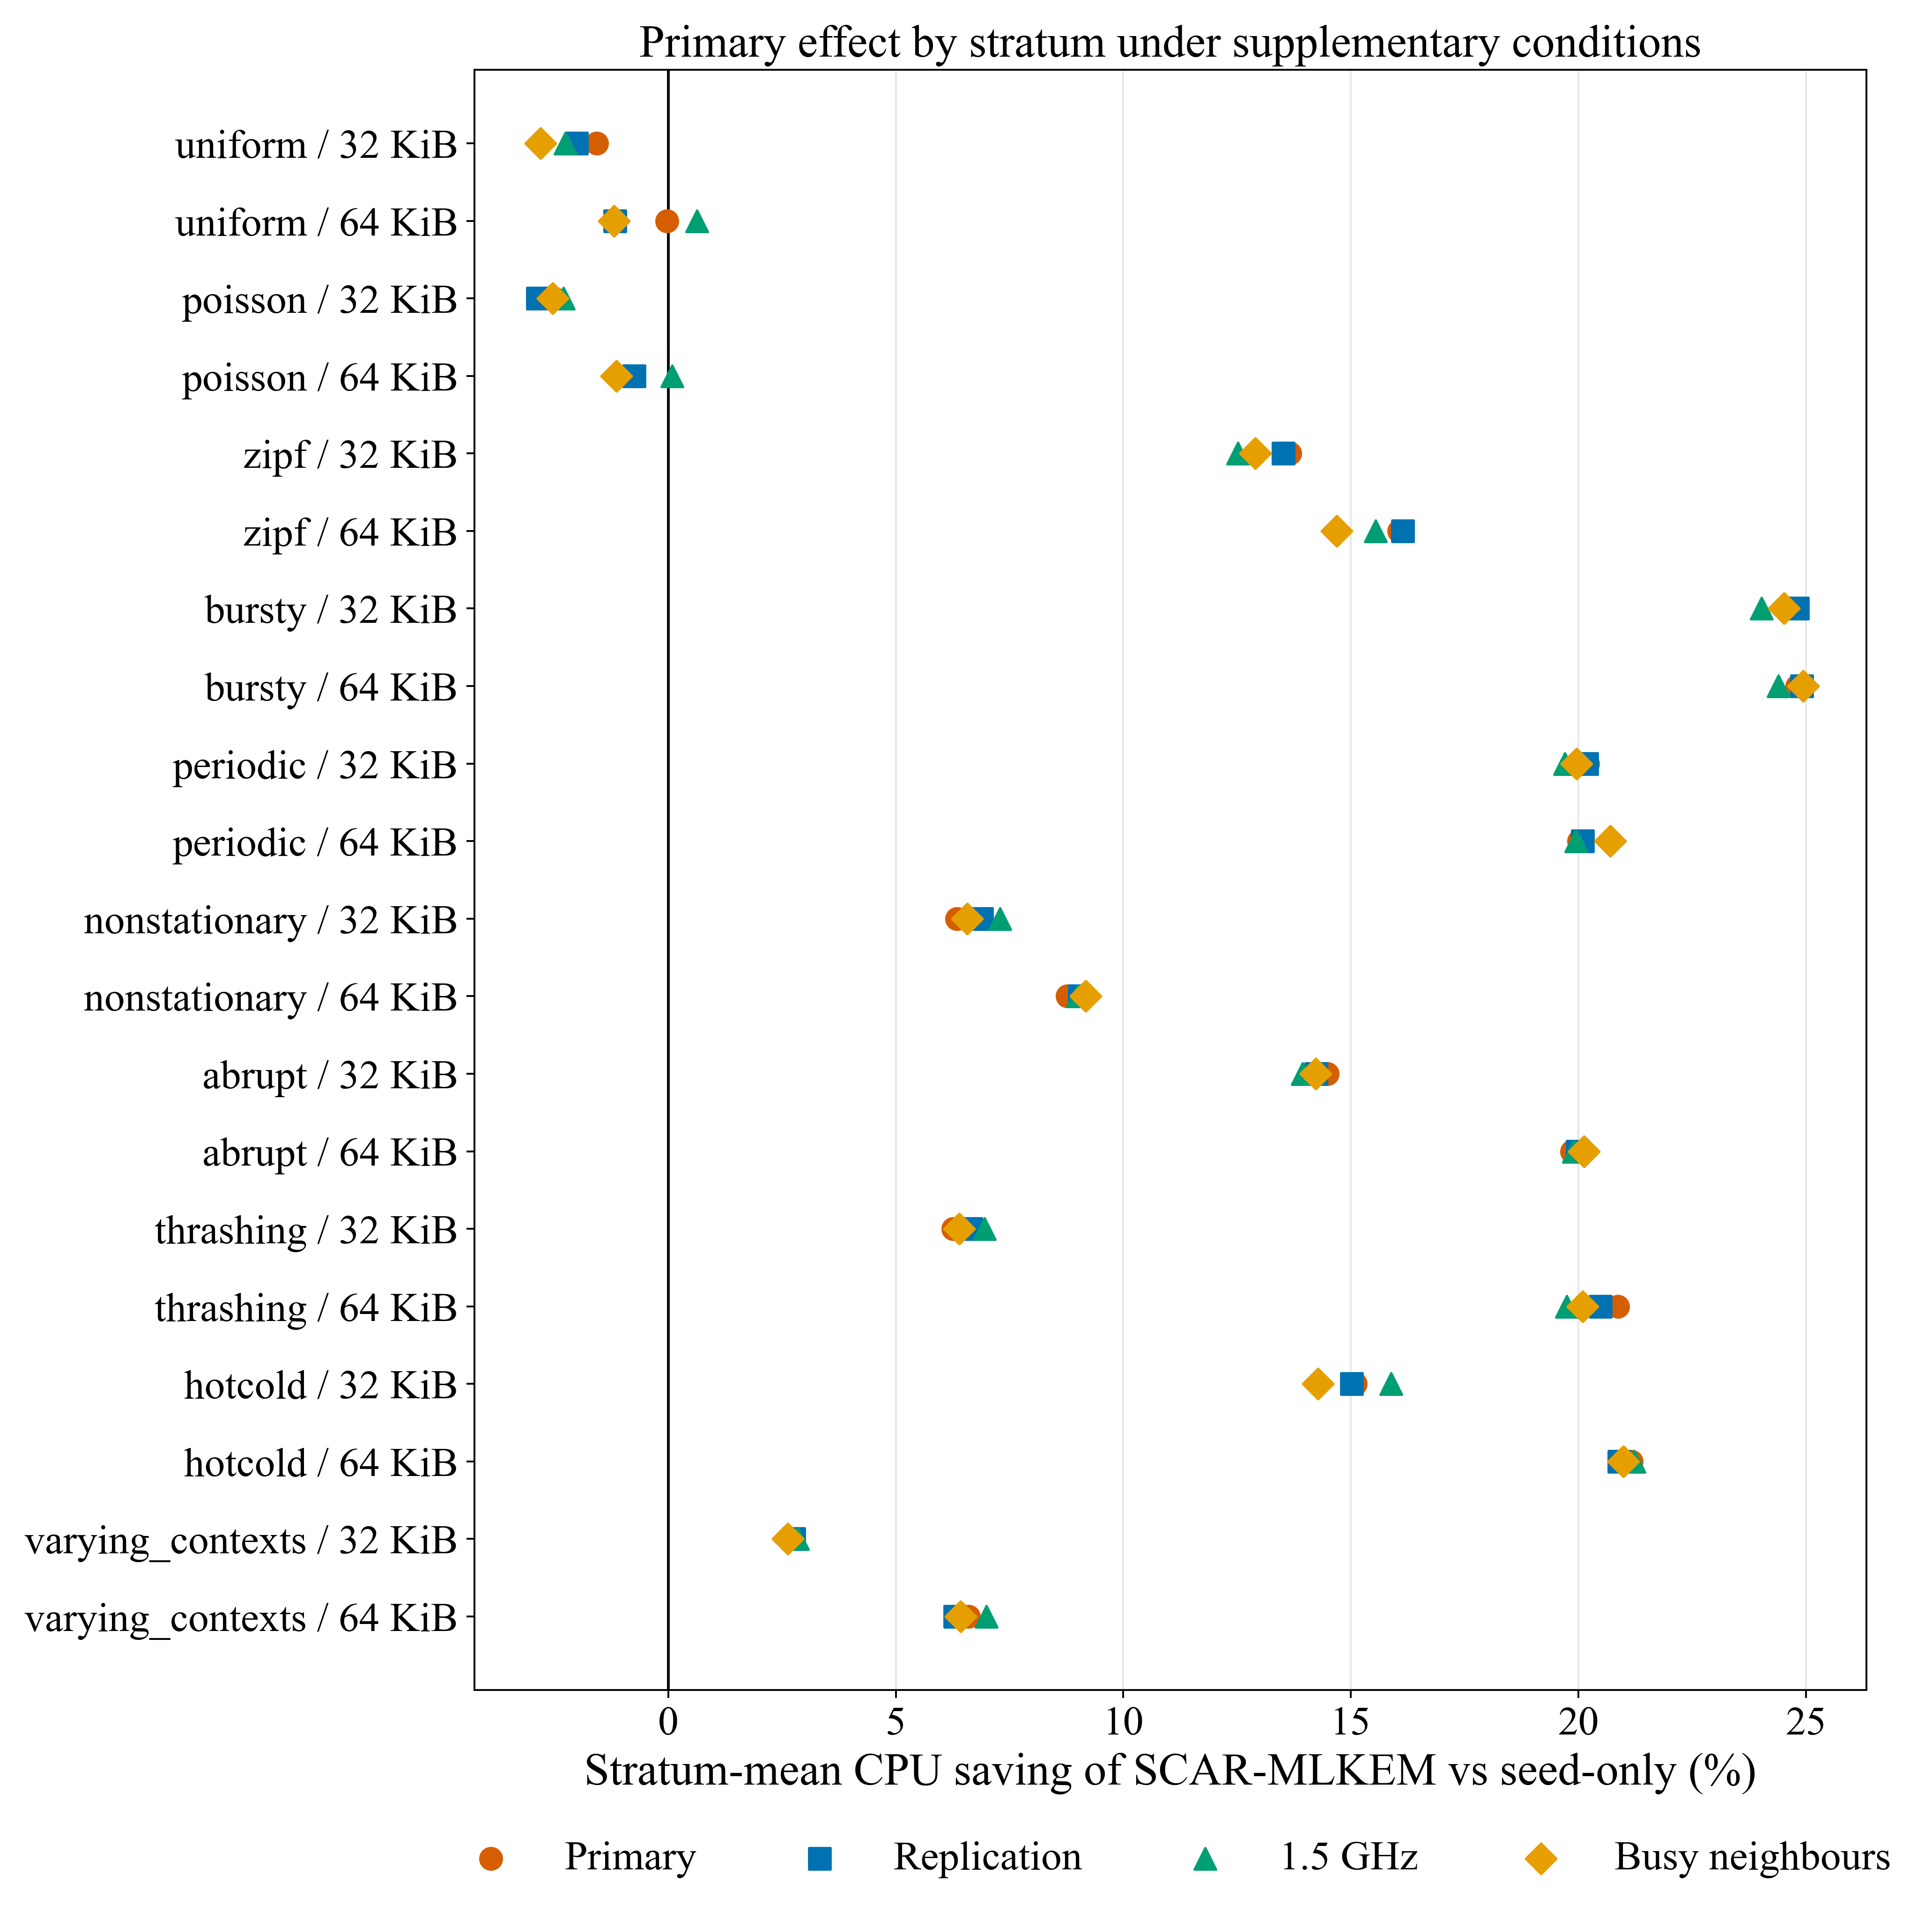

In [25]:
# One figure for the supplementary conditions: per-stratum saving of SCAR-MLKEM vs seed-only under each condition (structure across regimes).
cond_frames = {"Primary": test, "Replication": supp_frames["replication"], "1.5 GHz": supp_frames["frequency"], "Busy neighbours": supp_frames["interference"]}
markers = {"Primary": ("o", COLORS["scar"]), "Replication": ("s", COLORS["public_s3"]), "1.5 GHz": ("^", COLORS["sieve"]), "Busy neighbours": ("D", COLORS["tiny"])}
fig, ax = plt.subplots(figsize=(11.5, 11.5))
ypos = np.arange(len(order))[::-1]
for k, f in cond_frames.items():
    P2 = f[f.status.eq("passed")]
    w = P2.pivot_table(index=["stratum", "seed", "arena_bytes"], columns="setting", values="cpu_us").reset_index().rename_axis(columns=None)
    per = (100 * (w["none"] - w["scar"]) / w["none"]).groupby(w.stratum).mean().reindex(order)
    ax.scatter(per.values, ypos, marker=markers[k][0], s=90, color=markers[k][1], label=k, zorder=3)
ax.axvline(0, color="black", linewidth=1.2)
ax.set_yticks(ypos); ax.set_yticklabels(order); ax.grid(axis="x", alpha=0.3)
ax.set_xlabel("Stratum-mean CPU saving of SCAR-MLKEM vs seed-only (%)"); ax.set_title("Primary effect by stratum under supplementary conditions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=4)
check_font_sizes(fig)
save_figure(fig, "supplementary_conditions", pd.concat([f[["session_id", "setting", "cpu_us"]].assign(condition=k) for k, f in cond_frames.items()]))

**Interpretation.** All 1360 supplementary processes completed without a native failure. The primary effect is stable under every condition: 11.73 % (11.57–11.88 %) on a second set of 60 reserved seeds, 11.76 % (11.62–11.91 %) at a pinned 1.5 GHz, where every policy is about 1.6 times slower (seed-only 60.8 µs, SCAR-MLKEM 53.7 µs) but the relative saving is unchanged, and 11.52 % (11.34–11.69 %) with busy loops on the three neighbouring cores. The increment over public S3-FIFO is likewise reproduced (1.25 %, 1.73 % and 1.11 %). The per-stratum pattern of the figure is the same in all four conditions, including the losses in uniform and Poisson traffic and the gains of 20–25 % in bursty, periodic, hot-cold and thrashing traffic at 64 KiB. Lifecycle discipline is the quantity that depends on the operating system, not on the method: with busy neighbours the responder shares the memory system and scheduler with three saturated cores and every secret-retaining policy records late clears (SCAR-MLKEM 10 in 3 of 40 sessions, maximum lateness 3.4 ms; LeCaR 15, 4.6 ms), and p99 response rises to 140–160 µs with the board at 68 °C; under `SCHED_FIFO` the same four policies record no late clear in 160 sessions and their p99 falls to 46–50 µs. Replication and interference therefore confirm the CPU result, and the real-time run shows that the late clears observed elsewhere are scheduling latency that a real-time responder removes.

## 10. Offline optimum, seed sufficiency and cost-model calibration

**Question.** How far is the achieved public-record hit rate from the offline optimum (Belady's MIN with the arena's entry capacity); how quickly do the primary intervals narrow with the number of reserved seeds; and does the frozen cost model predict the measured per-session saving? **Method.** All three are computations on the saved test traces and need no new acquisition. Belady is evaluated on the request sequence of each session with capacity $\lfloor(\text{arena}-1504)/3584\rfloor$ public entries (8 at 32 KiB, 17 at 64 KiB). Seed sufficiency subsamples $n=2\ldots6$ seeds per stratum (100 draws each) and reports the half-width of the bootstrap interval. Calibration predicts the per-session saving as $h_P d_P + h_S d_S - a_P n_P - a_S n_S$ from observed hit and admission counts and compares it with the measured paired difference.

In [26]:
def belady_hits(keys, capacity):
    # Offline optimum (Belady's MIN): on a miss with a full cache evict the entry whose next use is farthest;
    # a key with no further use is not inserted. Returns the hit fraction.
    n = len(keys); next_use = [n] * n; last = {}
    for i in range(n - 1, -1, -1):
        next_use[i] = last.get(keys[i], n); last[keys[i]] = i
    cache, hits = {}, 0
    for i, k in enumerate(keys):
        if k in cache:
            hits += 1
        elif next_use[i] < n:
            if len(cache) >= capacity:
                victim = max(cache, key=cache.get)
                if cache[victim] > next_use[i]:
                    del cache[victim]
                else:
                    continue
            cache[k] = None
        if k in cache:
            cache[k] = next_use[i]
            if cache[k] >= n:
                del cache[k]
    return hits / n
raw_test = ROOT / relocate(conf_spec["raw_dir"])
bel_rows = []
for row in conf_spec["plan"]:
    if row["setting"] != "none":
        continue
    keys = pd.read_csv(raw_test / (row["session_id"] + ".stdout.csv"), usecols=["key_id"]).key_id.astype(int).tolist()
    capacity = (row["arena_bytes"] - 1504) // 3584
    bel_rows.append(dict(stratum=f"{row['family']} / {row['arena_bytes'] // 1024} KiB", seed=row["seed"], arena_bytes=row["arena_bytes"], capacity=capacity, belady_hit=belady_hits(keys, capacity)))
belady = pd.DataFrame(bel_rows)
ach = P[P.setting.isin(["public_s3", "scar"])].pivot_table(index=["stratum", "seed", "arena_bytes"], columns="setting", values="public_hit").reset_index().rename_axis(columns=None)
belady = belady.merge(ach, on=["stratum", "seed", "arena_bytes"], validate="one_to_one")
bel_strata = belady.groupby("stratum")[["belady_hit", "public_s3", "scar"]].mean().loc[order] * 100
bel_table = bel_strata.rename(columns={"belady_hit": "Belady optimum (%)", "public_s3": "Public S3-FIFO (%)", "scar": "SCAR-MLKEM (%)"})
bel_table["SCAR gap to optimum (pp)"] = bel_table["Belady optimum (%)"] - bel_table["SCAR-MLKEM (%)"]
bel_table["Upper-bound saving via public hits (%)"] = bel_strata["belady_hit"] / 100 * (COSTS["C00"] - COSTS["C10"]) / 1000 / complete.groupby("stratum")["none"].mean().loc[order] * 100
save_table(bel_table.rename_axis("Stratum").reset_index(), "belady_bound")

,Stratum,Belady optimum (%),Public S3-FIFO (%),SCAR-MLKEM (%),SCAR gap to optimum (pp),Upper-bound saving via public hits (%)
0,uniform / 32 KiB,39.667,12.817,10.600,29.067,9.311
1,uniform / 64 KiB,58.083,27.133,23.100,34.983,13.712
2,poisson / 32 KiB,39.633,12.300,10.617,29.017,9.470
3,poisson / 64 KiB,58.033,26.500,21.967,36.067,13.910
4,zipf / 32 KiB,72.850,62.133,63.667,9.183,17.205
5,zipf / 64 KiB,84.183,75.700,73.783,10.400,19.847
6,bursty / 32 KiB,97.200,95.833,94.283,2.917,23.875
7,bursty / 64 KiB,97.200,97.200,94.400,2.800,23.891
8,periodic / 32 KiB,86.717,83.850,82.733,3.983,20.496
9,periodic / 64 KiB,90.733,86.083,83.067,7.667,21.498


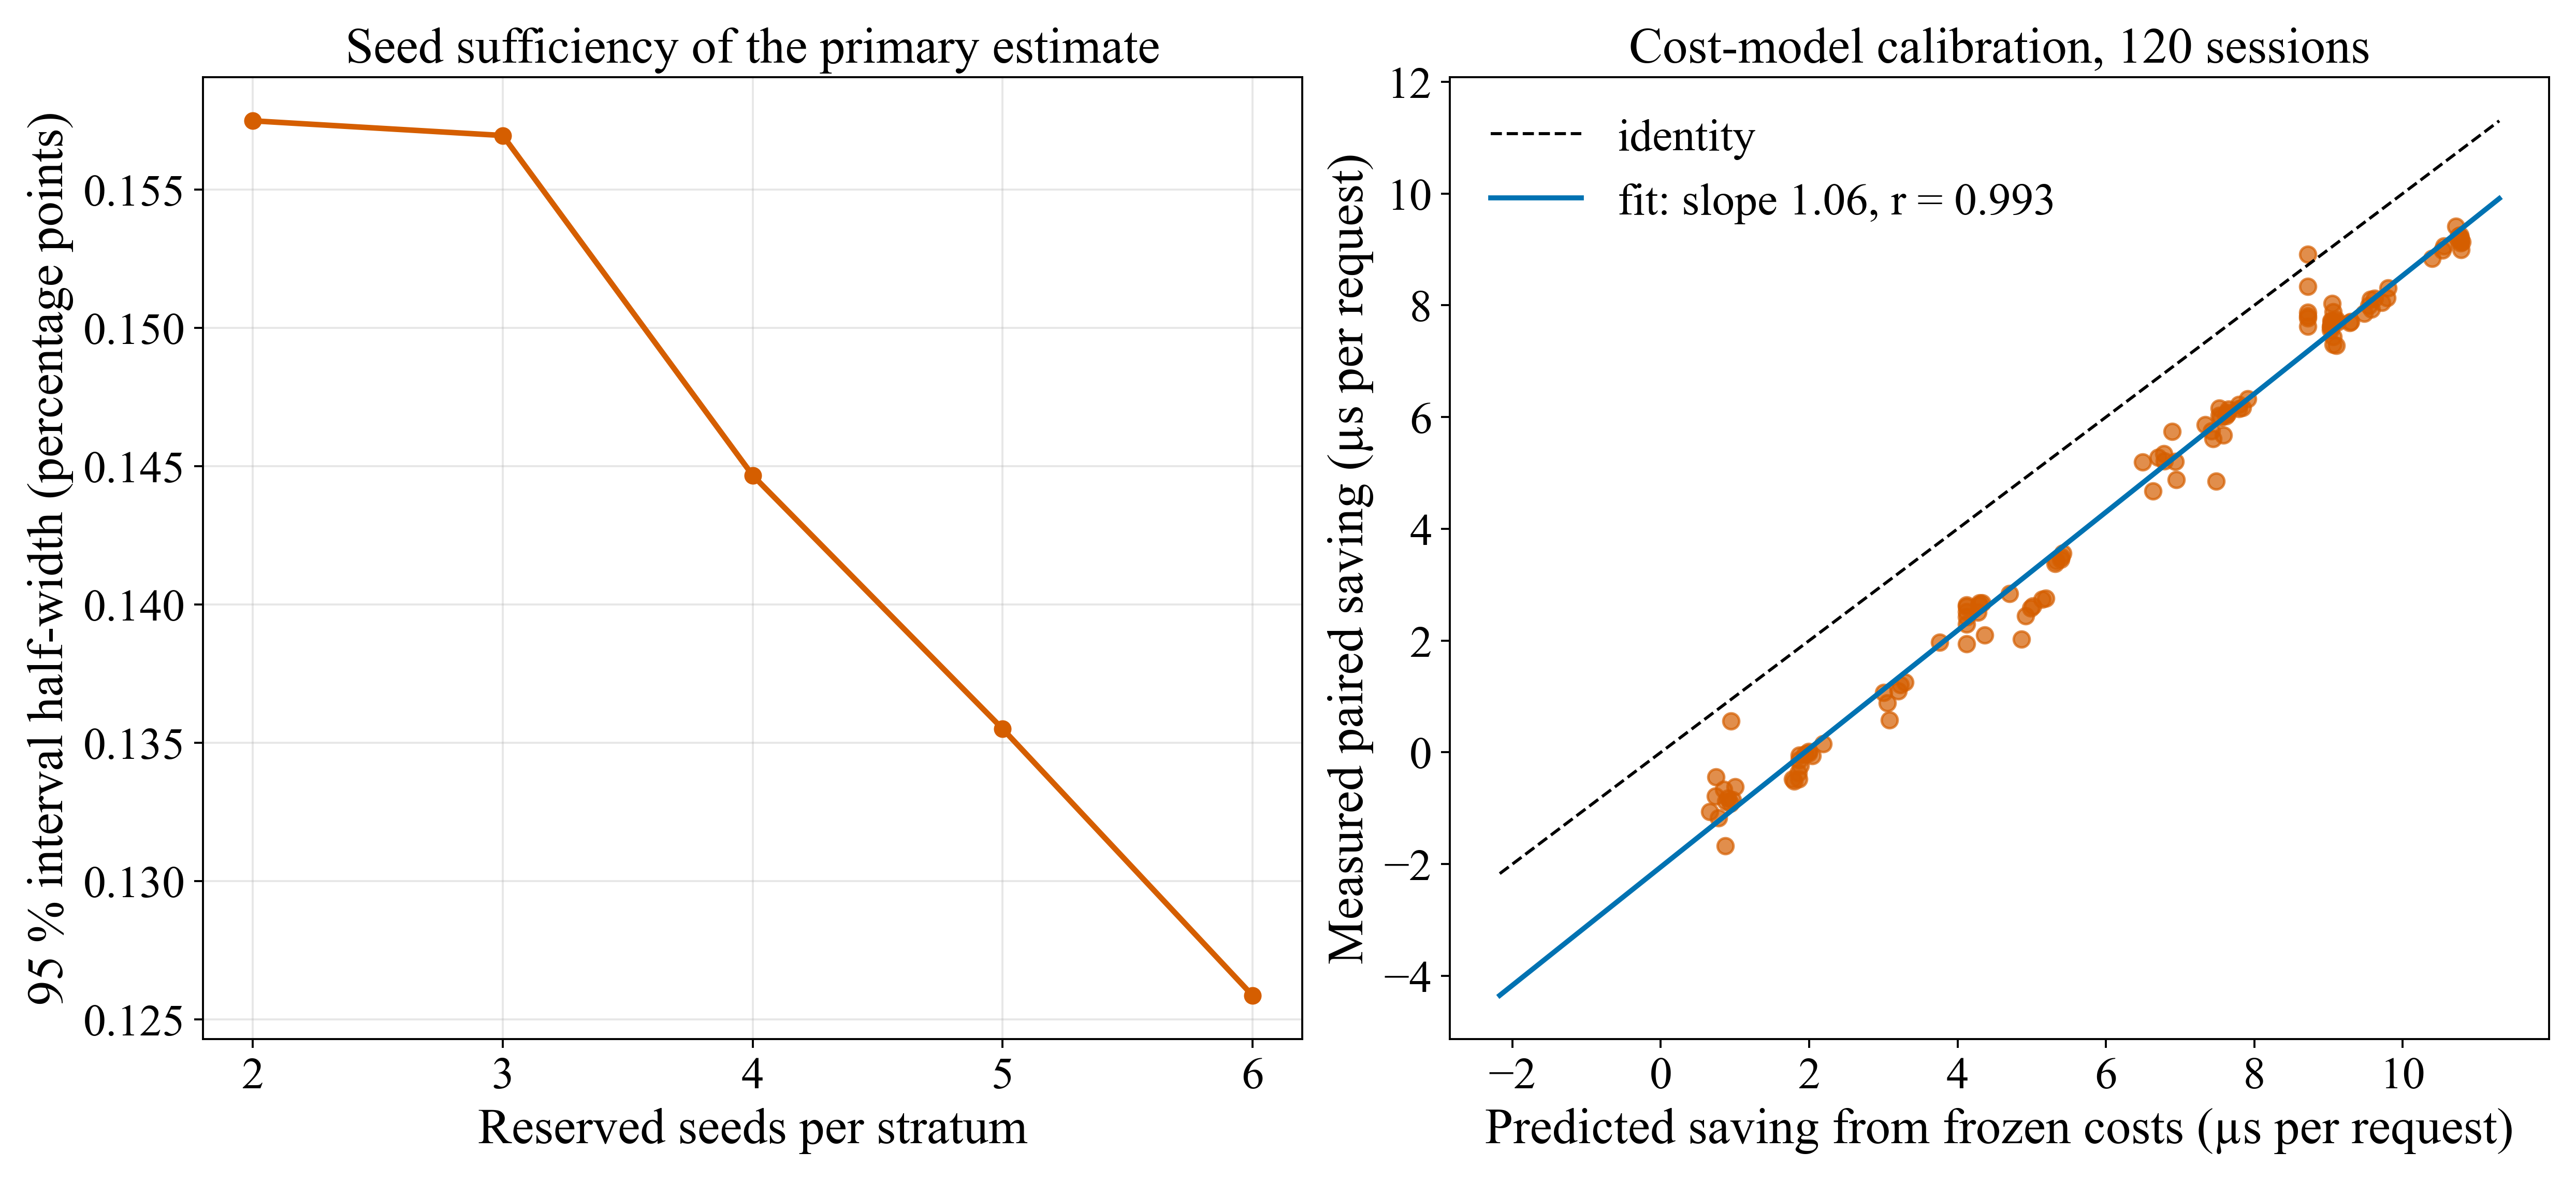

,Sessions,Pearson r,Slope,Intercept (µs),Mean predicted (µs),Mean measured (µs),Mean absolute error (µs)
0,120,0.993,1.058,-2.052,6.193,4.503,1.693


In [31]:
# Seed sufficiency: interval half-width of the primary relative saving as a function of seeds per stratum.
rng = np.random.default_rng(RNG_SEED); seed_rows = []
by_stratum = {s: g for s, g in complete.groupby("stratum")}
for n in range(2, 7):  # one seed per stratum leaves nothing to resample
    widths, points = [], []
    for _ in range(100):
        sub = pd.concat([g.sample(n=n, replace=False, random_state=int(rng.integers(1 << 31))) for g in by_stratum.values()])
        pt, lo, hi, _ = stratified_bootstrap(sub.delta_scar, sub.stratum, sub["none"], reps=1000, seed=int(rng.integers(1 << 31)))
        widths.append((hi - lo) / 2); points.append(pt)
    seed_rows.append(dict(seeds=n, sessions=20 * n, half_width=float(np.mean(widths)), point_sd=float(np.std(points))))
seed_curve = pd.DataFrame(seed_rows)
# Cost-model calibration: predicted vs measured per-session saving.
calib = P[P.setting == "scar"].set_index(["stratum", "seed", "arena_bytes"])
none_idx = P[P.setting == "none"].set_index(["stratum", "seed", "arena_bytes"])
pred = (calib.public_hit * (COSTS["C00"] - COSTS["C10"]) + calib.secret_hit * (COSTS["C00"] - COSTS["C01"])
        - calib.public_admitted * (COSTS["addP"] + COSTS["eraseP"]) - calib.secret_admitted * (COSTS["addS"] + COSTS["eraseS"])) / 1000
measured = none_idx.cpu_us - calib.cpu_us
cal = pd.DataFrame({"predicted": pred, "measured": measured}).dropna()
slope, intercept = np.polyfit(cal.predicted, cal.measured, 1); r = np.corrcoef(cal.predicted, cal.measured)[0, 1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.3))
axes[0].plot(seed_curve.seeds, seed_curve.half_width, marker="o", linewidth=2.2, color=COLORS["scar"])
axes[0].set_xlabel("Reserved seeds per stratum"); axes[0].set_ylabel("95 % interval half-width (percentage points)"); axes[0].set_title("Seed sufficiency of the primary estimate")
axes[0].set_xticks(range(2, 7)); axes[0].grid(alpha=0.3)
axes[1].scatter(cal.predicted, cal.measured, s=40, color=COLORS["scar"], alpha=0.7)
lim = [min(cal.predicted.min(), cal.measured.min()) - 0.5, max(cal.predicted.max(), cal.measured.max()) + 0.5]
axes[1].plot(lim, lim, color="black", linewidth=1.2, linestyle="--", label="identity")
axes[1].plot(lim, [slope * x + intercept for x in lim], color=COLORS["public_s3"], linewidth=2, label=f"fit: slope {slope:.2f}, r = {r:.3f}")
axes[1].set_xlabel("Predicted saving from frozen costs (µs per request)"); axes[1].set_ylabel("Measured paired saving (µs per request)"); axes[1].set_title("Cost-model calibration, 120 sessions")
axes[1].legend(loc="upper left")
check_font_sizes(fig)
save_figure(fig, "seed_sufficiency_and_calibration", pd.concat([seed_curve.assign(kind="seed_curve"), cal.reset_index().assign(kind="calibration")]))
save_table(pd.DataFrame([{"Sessions": len(cal), "Pearson r": r, "Slope": slope, "Intercept (µs)": intercept, "Mean predicted (µs)": cal.predicted.mean(), "Mean measured (µs)": cal.measured.mean(),
                          "Mean absolute error (µs)": (cal.measured - cal.predicted).abs().mean()}]), "cost_model_calibration")

In [32]:
# Sensitivity of the aggregate to the weighting scheme, and equivalence tests for memory and p95 response.
weights = []
pt_eq, lo_eq, hi_eq, _ = stratified_bootstrap(complete.delta_scar, complete.stratum, complete["none"])
pooled = 100 * complete.delta_scar.mean() / complete["none"].mean()
fam = complete.groupby("family").apply(lambda g: pd.Series({"d": g.delta_scar.mean(), "n": g["none"].mean()}), include_groups=False)
weights.append({"Weighting": "Equal strata (prespecified)", "Relative saving (%)": pt_eq, "95 % CI (%)": f"[{lo_eq:.3f}, {hi_eq:.3f}]"})
weights.append({"Weighting": "Pooled sessions", "Relative saving (%)": pooled, "95 % CI (%)": "—"})
weights.append({"Weighting": "Equal families", "Relative saving (%)": 100 * fam.d.mean() / fam.n.mean(), "95 % CI (%)": "—"})
weights.append({"Weighting": "Median session", "Relative saving (%)": (100 * complete.delta_scar / complete["none"]).median(), "95 % CI (%)": "—"})
save_table(pd.DataFrame(weights), "weighting_sensitivity")
def tost(x, margin):
    # Two one-sided paired t-tests on log ratios against symmetric margins ±margin.
    n = len(x); m = x.mean(); se = x.std(ddof=1) / np.sqrt(n)
    p_low = stats.t.sf((m + margin) / se, n - 1); p_high = stats.t.sf((margin - m) / se, n - 1)
    return m, max(p_low, p_high)
rss = np.log(P[P.setting == "scar"].set_index(["stratum", "seed", "arena_bytes"]).peak_rss_bytes / P[P.setting == "none"].set_index(["stratum", "seed", "arena_bytes"]).peak_rss_bytes).dropna()
p95 = np.log(tail_wide["p95"]["scar"] / tail_wide["p95"]["none"]).dropna()
eq_rows = []
for name, x, margin in (("Peak RSS ratio SCAR / seed-only", rss, np.log(1.02)), ("p95 response ratio SCAR / seed-only", p95, np.log(1.05))):
    m, p = tost(x, margin)
    eq_rows.append({"Quantity": name, "Sessions": len(x), "Geometric mean ratio": float(np.exp(m)), "Equivalence margin": f"±{(np.exp(margin) - 1) * 100:.0f} %", "TOST p": p, "Equivalent at α = 0.05": "yes" if p < 0.05 else "no"})
save_table(pd.DataFrame(eq_rows), "equivalence_tests")

,Weighting,Relative saving (%),95 % CI (%)
0,Equal strata (prespecified),11.795,"[11.671, 11.920]"
1,Pooled sessions,11.795,—
2,Equal families,11.795,—
3,Median session,13.691,—


,Quantity,Sessions,Geometric mean ratio,Equivalence margin,TOST p,Equivalent at α = 0.05
0,Peak RSS ratio SCAR / seed-only,120,1.003,±2 %,5.25e-45,yes
1,p95 response ratio SCAR / seed-only,120,1.013,±5 %,4.79e-13,yes


**Interpretation.** Belady's clairvoyant optimum bounds what any public-record policy can reach with the same arena: SCAR-MLKEM is within 1–8 percentage points of it in bursty, periodic, abrupt, thrashing and hot-cold traffic at 64 KiB, but 19–36 points below it in uniform, Poisson, nonstationary and varying-context traffic, where an online policy cannot know which of the 64 contexts will recur next; the corresponding upper bound on public-hit saving is 9–24 % by stratum, so the headroom left for any causal policy lies in those sparse regimes. Six reserved seeds per stratum are sufficient: the 95 % interval half-width of the primary estimate falls from 0.16 percentage points at two seeds to 0.13 at six, against an effect of 11.8 points. The frozen cost model is a good but biased predictor of the measured saving: across 120 sessions the correlation is 0.993 with slope 1.06, and the intercept of −2.1 µs shows that lookups, deadline maintenance, monitoring and the final clear, which the four-state model omits, cost about 1.7 µs per request on average. The aggregate is insensitive to weighting because the design is balanced (equal strata, pooled sessions and equal families all give 11.79 %; the median session saves 13.7 %), and the two-one-sided tests establish equivalence of SCAR-MLKEM and seed-only reconstruction in peak RSS within ±2 % (geometric mean ratio 1.003) and in p95 response within ±5 % (ratio 1.013), both with $p<10^{-12}$.

## 11. Scientific conclusions and limits

**Supported by this confirmation.** On 120 reserved sessions spanning ten workload families and two memory budgets on Raspberry Pi 5, the frozen SCAR-MLKEM controller reduces the complete request-phase CPU cost of ML-KEM-768 decapsulation by 11.79 % (95 % interval 11.67–11.92 %, one-sided lower bound 11.69 %) relative to standard seed-only reconstruction, without changing the algorithm, its parameters or its key sizes. Every cryptographic check passed, no retained secret exceeded its 10 ms lifetime, peak memory and p95 response are equivalent to the baseline within ±2 % and ±5 %, and throughput per CPU-second rises by 13 %. After Holm adjustment the controller is also lower in CPU than public S3-FIFO (1.40 %, 1.26–1.53 %), SIEVE (7.27 %), LeCaR (9.50 %) and TinyLFU (6.04 %). The effect replicates on a second set of reserved seeds (11.73 %), at a pinned 1.5 GHz (11.76 %) and under saturated neighbouring cores (11.52 %); the cost model that drives the controller predicts the measured saving with correlation 0.993.

**Not supported.** A large margin over the best fixed cache: the adaptive increment is 1.1–1.7 % across conditions, bounded by the secret-retention ceiling established in Notebook 05. Universal benefit: uniform and Poisson traffic lose up to 2.5 %, remain 29–36 points below the clairvoyant optimum, and should run with retention disabled in deployments dominated by such traffic. Energy: no electrical measurement exists; CPU time is not energy. Hard real-time lifetime guarantees under the default scheduler: late clears appear whenever neighbouring cores are saturated (10 for the frozen method in 40 such sessions) and disappear under `SCHED_FIFO`, so they are an operating-system property that a deployment must address by scheduling policy, not by the cache.

**Scope of inference.** One board, one software stack, controlled synthetic schedules rather than production key-access traces, equal-weight strata and 6 reserved seeds per stratum, which the seed-sufficiency curve shows to be adequate for the aggregate but not for per-stratum inference. The effect is an estimate for this mixture of workloads, not for a deployment population, and the comparators are the project's own adaptations of published policies. Replication on another device, real key-access traces, calibrated energy, cloud quantum simulation, a second constrained device and national-standard conformity remain open.